# Mendelian Randomization with *Hypolimnas misippus*: Using Genetic Variants as Instrumental Variables (R + `ivreg`)

**Course:** *Genome-Wide Association Studies (GWAS) for Evolutionary Biology* (prstats.org)
**Topic:** Causal inference. Getting rid of confounders with **instrumental variables** and **Mendelian randomization (MR)**.

This notebook **continues** the meta-analysis notebook (`Meta_Analysis_GWAS_GWAMA_METAL_Hypolimnas_misippus_Colab.ipynb`). That notebook ended with a table of the **top-ranked variants** from the meta-analysis of the *m*-versus-*i* wing-morph GWAS (`top_variants_meta.tsv`). Here those variants become the **instrumental variables, Z**, in a causal analysis

$$Z \;\longrightarrow\; X \;\longrightarrow\; Y, \qquad C \;\longrightarrow\; X,\quad C \;\longrightarrow\; Y,$$

where

* **Z** = genotype (dosage of the effect allele) at a top-ranked variant, **read from the ANGSD genotype likelihoods** of the 20 butterflies;
* **X** = wing colour (the exposure);
* **Y** = a fitness-related outcome (a simulated "fitness index"; there is no real Y in our data set);
* **C** = **habitat**, an **unmeasured confounder** that influences both wing colour and fitness. It is simulated and we **never use it in the instrumental-variable analysis**.

The punchline: the naive regression `Y ~ X` is **biased** by the confounder, and the instrumental-variable estimate (`ivreg(Y ~ X | Z)`) **recovers the true causal effect without ever seeing C**.

### What you will do in this notebook

1. Install ANGSD, SAMtools and **R with the `ivreg` package** (everything via Conda) and mount Google Drive.
2. Read the **top variants** of the meta-analysis, choose **independent** ones as instruments, and add the best variant of the **M locus** as a positive control.
3. Run **ANGSD** on all 20 butterflies at exactly those sites and convert genotype likelihoods into **genotype dosages (Z)**.
4. In **R**: simulate the unmeasured confounder C, the exposure X and the outcome Y with a **known causal effect**; show that **ordinary regression is biased**; run **two-stage least squares by hand and with `ivreg`**; read the diagnostics (weak-instrument *F*, Wu-Hausman, Sargan).
5. Understand **why** it works (or fails) with experiments: weak instruments, many instruments, sample size, pleiotropy, and a confounded instrument, each with a clear plot.
6. Use the **summary-statistics view of MR** (Wald ratio, inverse-variance-weighted and MR-Egger) that connects directly to GWAS summary statistics.
7. Use the **real morph** as the exposure with the **M-locus** variant as the instrument.

> **Honest framing (please read).** (i) We have only **20 butterflies**, which is tiny for MR. (ii) The top variants of the previous notebook are **not genome-wide significant** (no variant passes the Bonferroni threshold), so by themselves they are **not credible instruments for the real morph**. They are used here, as requested, to show the machinery on real genotypes, and the notebook uses them to teach exactly *why* such variants are problematic (winner's curse, weak instruments). (iii) **X's genetic effect and Y are simulated** so that the truth is known; no biological conclusion about butterflies should be drawn from the estimated numbers. The real biology enters only in Section 9 (the M locus and the real morph).

## 0. Background: correlation, confounding and instrumental variables

### 0.1 Why is `Y ~ X` not enough?

Suppose we want to know whether **wing colour (X) causes a change in fitness (Y)**, for example through predation by birds that avoid some colours. We could measure both on many butterflies and regress `Y ~ X`. The slope is the **association** between X and Y. It equals the **causal effect** only if nothing else drives both X and Y.

A **confounder C** is a variable that influences both. Imagine that **habitat** matters: butterflies of one colour form are more often found in open sunny meadows (where the model species they mimic is common), and the same meadows have different predation, food and weather, all of which change fitness. Then colour and fitness are associated **even if colour has no causal effect at all**.

```
        C  (habitat; unmeasured)
       / \
      v   v
      X ---> Y        X = wing colour,  Y = fitness index
```

If we regress `Y ~ X` and **omit C**, the slope is $\beta + \gamma\,\mathrm{Cov}(X,C)/\mathrm{Var}(X)$: the true effect $\beta$ plus a **confounding bias**. Adding more data does **not** remove the bias: it only makes us more certain about the wrong number.

*Adjusting* for C (`Y ~ X + C`) would work, but **only if C is measured** and measured well. Real confounders (habitat, diet, population structure, behaviour, the environment in which the butterfly grew up) are usually **unmeasured or unknown**. This is the situation instrumental variables are made for.

### 0.2 The idea of an instrumental variable

An **instrument Z** is a variable that **pushes X around but has no other route to Y**:

```
   Z ------> X ------> Y
             ^         ^
              \       /
                 C
```

The three conditions (these are the **instrumental-variable assumptions**) are:

| # | Assumption | In words | Can we test it? |
|---|---|---|---|
| 1 | **Relevance** | Z is **associated with X** (strongly enough). | **Yes**: first-stage regression, *F*-statistic. |
| 2 | **Independence (exchangeability)** | Z is **independent of the confounders C** (it shares no common cause with Y). | **No** (C is unmeasured); only indirectly. |
| 3 | **Exclusion restriction** | Z affects Y **only through X** (no direct path, no pleiotropy). | **No**; with several instruments, partial tests (Sargan, MR-Egger). |

Why is a **genetic variant** such a natural instrument? **Mendel's laws.** At meiosis the two alleles of a parent are transmitted at random (**Mendel's law of segregation**), and different loci are transmitted independently (**law of independent assortment**, apart from linkage). So the allele a butterfly carries is assigned **at conception, like a randomised trial**, before habitat, diet or predators can act on it. This is why the method is called **Mendelian randomization**. Genotype also cannot be changed *by* the outcome (no reverse causation).

In human genetics the textbook example is a variant in a gene that raises BMI (Z), used to ask whether BMI (X) causes cancer (Y) in spite of lifestyle confounders (C). The slide from the course shows exactly that:

```
SNP ──────► Insulinemia ──────► Endometrial cancer          (Mendelian randomization)
```

### 0.3 The estimator: Wald ratio and two-stage least squares (2SLS)

Take a single binary or continuous instrument Z. Because Z affects Y **only through X**,

$$\underbrace{\mathrm{Cov}(Z,Y)}_{\text{reduced form}} \;=\; \beta\;\underbrace{\mathrm{Cov}(Z,X)}_{\text{first stage}}
\qquad\Longrightarrow\qquad
\hat\beta_{IV}=\frac{\mathrm{Cov}(Z,Y)}{\mathrm{Cov}(Z,X)}=\frac{\hat\beta_{ZY}}{\hat\beta_{ZX}}\quad(\textbf{Wald ratio}).$$

In words: *how much does Y change per allele* divided by *how much does X change per allele*. The confounder cancels because Z is independent of C.

With several instruments we use **two-stage least squares**:

1. **Stage 1 (first stage):** regress the exposure on the instruments, `X ~ Z1 + Z2 + ...`, and keep the **fitted values** $\hat X$. These contain only the part of X that is explained by genes, which is "clean" of C.
2. **Stage 2:** regress the outcome on the fitted exposure, `Y ~ X_hat`. The slope is the 2SLS estimate $\hat\beta_{2SLS}$.

(If you run the two regressions by hand, the *standard errors* of stage 2 are wrong because they ignore that $\hat X$ was estimated. `ivreg` fixes that. We will compare both in Section 6.6.)

### 0.4 Instrument strength, many instruments and allele scores

* The **first-stage *F*-statistic** measures relevance. A common rule of thumb is **F > 10**. When F is small the instrument is **weak**: the 2SLS estimate becomes noisy, **biased towards the confounded OLS estimate**, and its confidence intervals mislead.
* **Many weak instruments** make things worse in small samples: stage 1 **over-fits** (with 8 instruments and 20 butterflies, the fitted $\hat X$ simply copies the noise in X, including the part caused by C, so 2SLS slides towards OLS).
* An **allele score** (sum of the effect-allele dosages, optionally weighted) collapses many variants into **one** instrument with one degree of freedom. It is much less prone to over-fitting.

### 0.5 What can go wrong in real MR

| Problem | What it is | Consequence | How we examine it here |
|---|---|---|---|
| **Weak instrument** | small *F* | bias towards OLS, huge uncertainty | Section 6.10 |
| **Winner's curse** | the instrument was **selected** for being the most associated variant **in the same individuals** | first-stage effect and *F* are **over-estimated** | Sections 3 and 9 |
| **Horizontal pleiotropy** | the variant influences Y by a route that does not pass through X | **bias** | Section 8 |
| **Linkage disequilibrium (LD) / population structure** | the variant is correlated with a confounder (e.g., ancestry, habitat) | **bias** | Section 8 |
| **Genotype uncertainty (low coverage)** | at 1 to 2x depth genotypes are probabilistic | weaker first stage (measurement error in Z) | Sections 4 and 5 |
| **Small sample** | 20 butterflies | everything is noisy | Sections 6.9 and 6.11 |

### 0.6 What is real and what is simulated in this notebook

| Quantity | Real or simulated? | Comment |
|---|---|---|
| Z (genotype dosages of top variants) | **real** (ANGSD, from your BAM files) | read in Sections 3 to 5 |
| Real morph (m/i) | **real** | used for instrument discovery (the GWAS) and in Section 9 |
| C (habitat) | **simulated**, never used in the IV analysis | by construction independent of Z |
| X (wing-colour score) in Sections 6 to 8 | **simulated** from Z, C and noise | we choose how strong the genetic effect is |
| Y (fitness index) | **simulated** with a **known causal effect** of X | the answer we try to recover |

Simulating X (instead of using the real binary morph) lets us dial the **strength of the instrument**, which the real data cannot. In Section 9 we come back to the real morph.

### 0.7 The same idea from GWAS summary statistics (two-sample MR)

For each variant $j$ one needs only two GWAS effect sizes: its effect on the exposure, $\hat\beta_{ZX,j}$, and on the outcome, $\hat\beta_{ZY,j}$ (with standard error $\mathrm{SE}_{ZY,j}$). Each variant gives a **Wald ratio** $\hat\beta_{ZY,j}/\hat\beta_{ZX,j}$. The **inverse-variance-weighted (IVW)** estimate combines them (this is a fixed-effect meta-analysis of the Wald ratios, as in the previous notebook!):

$$\hat\beta_{IVW}=\frac{\sum_j \hat\beta_{ZX,j}\hat\beta_{ZY,j}\,\mathrm{SE}_{ZY,j}^{-2}}{\sum_j \hat\beta_{ZX,j}^{2}\,\mathrm{SE}_{ZY,j}^{-2}}.$$

**MR-Egger** adds an intercept to the same regression; a non-zero intercept signals **directional pleiotropy**. We implement both in Section 7 so that the link between "meta-analysis of GWAS" and "MR" is concrete.

## 1. Install ANGSD, SAMtools and R (with `ivreg`)

| Tool | What we use it for | How it is installed |
|---|---|---|
| **Conda** (Miniforge via `condacolab`) | installs everything below inside Colab | `pip install condacolab` |
| **ANGSD** | genotype likelihoods at the chosen sites | Bioconda |
| **SAMtools** | quick integrity check of BAM files | Bioconda |
| **R** | the causal-inference code | conda-forge (`r-base`) |
| **`ivreg`** (R package) | two-stage least squares with proper standard errors and diagnostics | conda-forge (`r-ivreg`) |
| **`rpy2`** | lets us run R code in Colab cells that start with `%%R`, in the same session as Python | conda-forge |

**The workflow in one line:** Python (ANGSD, file handling) → a plain-text table of genotype dosages on Google Drive → R (`ivreg`, simulations, plots).

Run the next cell. **Colab will restart the runtime by itself** when it finishes; this is normal. After the restart, continue with the cell after it (do *not* run the install cell again).

In [1]:
# Install Conda (Miniforge) inside Google Colab. The kernel restarts automatically afterwards.
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

✨🍰✨ Everything looks OK!


In [2]:
%%bash
# ANGSD and SAMtools from Bioconda (+ conda-forge for the dependencies).
mamba install -y -q -c conda-forge -c bioconda angsd samtools htslib 2>&1 | tail -n 5

In [3]:
%%bash
# R, the 'ivreg' package (and its helpers) and rpy2, all from conda-forge. This can take a few minutes.
mamba install -y -q -c conda-forge r-ivreg r-sandwich r-lmtest rpy2 2>&1 | tail -n 8

In [4]:
# in case R magic is not installed, uninstall all rpy2-related packages
!pip uninstall rpy2 rpy2-rinterface rpy2-robjects -y

# Install a known-working version
!pip install rpy2==3.5.1

Found existing installation: rpy2 3.5.1
Uninstalling rpy2-3.5.1:
  Successfully uninstalled rpy2-3.5.1
  Using cached rpy2-3.5.1-cp313-cp313-linux_x86_64.whl


In [5]:
%load_ext rpy2.ipython

In [6]:
%%R
library("matrixStats")
print("This line checks that R magic works fine")

[1] "This line checks that R magic works fine"


In [7]:
%%bash
echo "ANGSD:    $(angsd 2>&1 | grep -i -m1 'version')"
echo "samtools: $(samtools --version | head -n 1)"
echo "R:        $(R --version | head -n 1)"
Rscript -e 'suppressMessages(library(ivreg)); cat("ivreg:    ", as.character(packageVersion("ivreg")), "\n")'
python -c "import rpy2; print('rpy2:     ', rpy2.__version__)"

ANGSD:    	-> angsd version: 0.940-dirty (htslib: 1.24) build(Dec 15 2024 09:11:59)
samtools: samtools 1.24
R:        R version 4.5.3 (2026-03-11) -- "Reassured Reassurer"
ivreg:     0.6.8 
rpy2:      3.5.1


> **What do the checks tell you?** You should see a version for each tool. If `ivreg` or `rpy2` is missing, re-run the R installation cell above and read the messages it prints. The R code in this notebook is ordinary R: if `rpy2` cannot be installed in your session you can copy the R cells into any R environment (for instance RStudio) and read the two small text files that Section 5 writes to Google Drive.

## 2. Mount Google Drive and Locate the Results of the Previous Notebooks

Colab's local disk is wiped when the session ends, so inputs and outputs live on **Google Drive**. The next cell asks for permission to access your Drive.

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 2.1 Parameters and folder search

We need three things from the earlier notebooks:

* the **BAM files** (`bams/`, from the alignment notebook) and the sample table `phenotypes.tsv`;
* the **top variants** of the meta-analysis, `metaanalysis_HypMis/tables/top_variants_meta.tsv`;
* the table of **all meta-analysed variants** (`meta_results_all_variants.tsv.gz`), used only to pick the best variant of the M locus.

Edit the parameters in the first block if you want to change the analysis. The folder search finds everything automatically; if it picks the wrong folder, set `PROJECT_DIR_OVERRIDE`.

In [9]:
import os, re, json, gzip, glob, shutil, subprocess, time, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

# ================================================================ ANALYSIS PARAMETERS (edit here)
N_INSTRUMENTS = 8              # how many independent top variants of the meta-analysis to use as instruments Z
MIN_DIST_BP = 1_000_000        # two instruments on the same chromosome must be at least this far apart (crude "LD pruning")
ADD_M_LOCUS_CONTROL = True     # also add the best variant of the M locus (chromosome 26) as a positive-control instrument
M_LABEL = "26"                 # chromosome label that carries the M locus
PEAK_START, PEAK_END = 6_731_000, 6_743_400    # the M-locus window used in the meta-analysis notebook
MAX_UNINFORMATIVE = 0.5        # drop an instrument if more than this fraction of the 20 butterflies has NO reads at the site
MIN_MAPQ, MIN_BASEQ = 30, 20   # ANGSD read filters (identical to the earlier notebooks)
GL_MODEL = 2                   # ANGSD genotype-likelihood model (2 = GATK), as before
FORCE = False                  # True = redo ANGSD even if its output exists
THREADS = os.cpu_count() or 2

# If the automatic search fails or picks the wrong place, set the project folder (the one that contains 'bams') here, e.g.
# PROJECT_DIR_OVERRIDE = "/content/drive/MyDrive/GWAS"
PROJECT_DIR_OVERRIDE = None

# ================================================================ find the project folder on Google Drive
DRIVE_ROOT = Path("/content/drive/MyDrive")

def find_on_drive(name, kind, maxdepth=6):
    # Search Google Drive for a folder (kind='d') or file (kind='f') with an exact name.
    res = subprocess.run(["find", str(DRIVE_ROOT), "-maxdepth", str(maxdepth), "-type", kind, "-name", name], capture_output=True, text=True)
    return [Path(p) for p in res.stdout.splitlines() if p.strip()]

if PROJECT_DIR_OVERRIDE:
    PROJECT_DIR = Path(PROJECT_DIR_OVERRIDE)
else:
    hits = [p.parent for p in find_on_drive("metaanalysis_HypMis", "d") if (p / "tables" / "top_variants_meta.tsv").exists()]
    assert hits, ("Could not find 'metaanalysis_HypMis/tables/top_variants_meta.tsv' on your Google Drive. "
                  "Run the meta-analysis notebook first (its Section 11 writes this table), or set PROJECT_DIR_OVERRIDE above.")
    if len(hits) > 1:
        print("WARNING: several matching project folders found, using the first one:", *hits, sep="\n    ")
    PROJECT_DIR = hits[0]

BAM_DIR = PROJECT_DIR / "bams"
META_DIR = PROJECT_DIR / "metaanalysis_HypMis"
TOP_FILE = META_DIR / "tables" / "top_variants_meta.tsv"
ALL_FILE = META_DIR / "tables" / "meta_results_all_variants.tsv.gz"
assert BAM_DIR.is_dir(), f"{BAM_DIR} not found"
assert TOP_FILE.exists(), f"{TOP_FILE} not found: run the meta-analysis notebook first"

# ================================================================ output folders (on Drive = persistent)
OUT = PROJECT_DIR / "mendelian_randomization_HypMis"
D = {k: OUT / k for k in ["angsd", "tables", "figures"]}
for d in D.values():
    d.mkdir(parents=True, exist_ok=True)

for k, v in {"PROJECT_DIR": PROJECT_DIR, "MR_DIR": D["tables"], "THREADS": THREADS}.items():
    os.environ[k] = str(v)           # make these paths visible to bash cells and to R (Sys.getenv)

print("Project folder       :", PROJECT_DIR)
print("BAM folder           :", BAM_DIR, f"({len(list(BAM_DIR.glob('*.sorted.bam')))} BAM files)")
print("Meta-analysis tables :", TOP_FILE.parent)
print("Output folder        :", OUT)
print("CPU threads          :", THREADS)

Project folder       : /content/drive/MyDrive/GWAS
BAM folder           : /content/drive/MyDrive/GWAS/bams (455 BAM files)
Meta-analysis tables : /content/drive/MyDrive/GWAS/metaanalysis_HypMis/tables
Output folder        : /content/drive/MyDrive/GWAS/mendelian_randomization_HypMis
CPU threads          : 2


In [10]:
# Small helpers: run a shell command (log kept on Drive), skip finished steps, save a figure.
def run(cmd, log=None, check=True, show=12, quiet=False):
    if not quiet:
        print("$", cmd if len(cmd) < 600 else cmd[:600] + " ...")
    t0 = time.time()
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True, executable="/bin/bash")
    text = (r.stdout or "") + (r.stderr or "")
    if log is not None:
        Path(log).write_text(f"$ {cmd}\n\n{text}")
    if r.returncode != 0 and check:
        print(text[-3500:])
        raise RuntimeError(f"Command failed with exit code {r.returncode} (see the output above).")
    if show and text.strip() and not quiet:
        print("\n".join(text.strip().splitlines()[-show:]))
    if not quiet:
        print(f"[done in {time.time() - t0:.1f} s, exit code {r.returncode}]")
    return r

def done(*paths):
    return (not FORCE) and all(Path(p).exists() and Path(p).stat().st_size > 0 for p in paths)

def savefig(name):
    plt.savefig(D["figures"] / f"{name}.png", dpi=150, bbox_inches="tight")

## 3. Choose the Instruments from the Top Variants of the Meta-Analysis

### 3.1 Read the sample table and the top variants

The meta-analysis notebook ended with a table of the top-ranked variants (`top_variants_meta.tsv`). Its `chr` column holds the **chromosome label** (for example `28`), not the sequence name used in the BAM files (`JBBEEQ0100000xx.1`). We therefore first rebuild the mapping *label → sequence name*, exactly as in the earlier notebooks: from the BAM header (sequence names) and the reference FASTA (descriptions that contain the chromosome number).

In [11]:
# ---- the 20 butterflies (written by the alignment notebook)
pheno_path = PROJECT_DIR / "phenotypes.tsv"
if pheno_path.exists():
    pheno = pd.read_csv(pheno_path, sep="\t")
else:
    morph_file = (find_on_drive("Hypolimnas_misippus_CAMID_morph.txt", "f") or [None])[0]
    assert morph_file is not None, "phenotypes.tsv and Hypolimnas_misippus_CAMID_morph.txt not found: run the alignment notebook first."
    morph = pd.read_csv(morph_file, sep="\t"); morph.columns = ["sampleID", "morph"]
    bams = sorted(BAM_DIR.glob("*.sorted.bam"))
    pheno = pd.DataFrame({"sampleID": [b.name.replace(".sorted.bam", "") for b in bams]}).merge(morph, on="sampleID")
pheno = pheno[["sampleID", "morph"] + [c for c in ["mean_depth"] if c in pheno.columns]].copy()
pheno["bam"] = pheno.sampleID.map(lambda s: str(BAM_DIR / f"{s}.sorted.bam"))
pheno["x_morph"] = (pheno.morph == "m").astype(int)            # the REAL exposure: 1 = m morph, 0 = i morph
missing = [b for b in pheno.bam if not Path(b).exists() or not Path(b + ".bai").exists()]
assert not missing, f"{len(missing)} BAM files (or indexes) missing, e.g. {missing[:2]}"
print(f"{len(pheno)} butterflies with BAM + index. Morphs: {pheno.morph.value_counts().to_dict()}")

# ---- chromosome label -> sequence name
hdr = subprocess.run(["samtools", "view", "-H", pheno.bam.iloc[0]], capture_output=True, text=True).stdout
fai = pd.DataFrame({"contig": [l.split("\t")[1][3:] for l in hdr.splitlines() if l.startswith("@SQ")],
                    "length": [int(l.split("\t")[2][3:]) for l in hdr.splitlines() if l.startswith("@SQ")]})
fasta = sorted((PROJECT_DIR / "reference_HypMis_v2").glob("*.fa")) if (PROJECT_DIR / "reference_HypMis_v2").exists() else []
label_of = {}
if fasta:
    heads = subprocess.run(["grep", ">", str(fasta[0])], capture_output=True, text=True).stdout.splitlines()
    for h in heads:
        name, _, desc = h[1:].partition(" ")
        m_ = re.search(r"(?:chromosome|scaffold)[:\s_]+([A-Za-z0-9]+)", desc)
        if m_: label_of[name] = m_.group(1)
fai["label"] = fai.contig.map(label_of)
CONTIG_OF_LABEL = {lab: c for c, lab in zip(fai.contig, fai.label) if isinstance(lab, str)}
print(f"{len(CONTIG_OF_LABEL)} chromosome labels mapped to sequence names (e.g. label 26 -> {CONTIG_OF_LABEL.get(M_LABEL)})")

# ---- the top variants of the meta-analysis
top = pd.read_csv(TOP_FILE, sep="\t", dtype={"chr": str})
need = {"rank", "chr", "pos", "EA", "NEA", "P_FE"}
assert need <= set(top.columns), f"unexpected columns in {TOP_FILE.name}: {list(top.columns)}"
display(top[[c for c in ["rank", "chr", "pos", "EA", "NEA", "EAF_B1", "EAF_B2", "beta_B1", "beta_B2", "same_dir", "P_FE", "I2_%", "in_M_window"] if c in top.columns]].head(12))

20 butterflies with BAM + index. Morphs: {'m': 10, 'i': 10}
218 chromosome labels mapped to sequence names (e.g. label 26 -> JBBEEQ010000026.1)


,rank,chr,pos,EA,NEA,EAF_B1,EAF_B2,beta_B1,beta_B2,same_dir,P_FE,I2_%,in_M_window
0,1,28,14726976,A,C,0.409955,0.251544,3.349407,4.395158,True,0.000061,0.0,False
1,2,26,4643718,A,G,0.267257,0.343892,3.706826,3.574742,True,0.000062,0.0,False
2,3,13,9174425,A,C,0.314771,0.471115,2.981880,3.209624,True,0.000065,0.0,False
3,4,19,8668136,G,A,0.285578,0.343653,-3.677540,-3.600203,True,0.000071,0.0,False
4,5,5,2290681,C,A,0.314315,0.399957,4.150779,2.831565,True,0.000095,0.0,False
5,6,32,4255228,T,A,0.414893,0.250494,3.355811,4.272763,True,0.000112,0.0,False
6,7,32,7797921,C,T,0.252077,0.735952,-4.089645,-3.277727,True,0.000114,0.0,False
7,8,24,15359794,T,G,0.378288,0.402186,3.032036,3.904548,True,0.000115,0.0,False
8,9,25,13238682,G,A,0.264123,0.294990,3.480592,3.764794,True,0.000120,0.0,False
9,10,14,1664805,G,A,0.452326,0.580542,2.963226,3.260962,True,0.000128,0.0,False


### 3.2 Pick independent variants, and add the M-locus variant as a positive control

Three practical rules for choosing instruments:

1. **Independence of the instruments from each other.** Neighbouring variants are in **linkage disequilibrium (LD)**: they carry the *same* information and would be counted several times. The standard remedy is **LD clumping/pruning**. We use a simple, conservative version: keep the best-ranked variant per chromosome region, and never two variants closer than `MIN_DIST_BP` on one chromosome (variants on different chromosomes are unlinked).
2. **Use a threshold for relevance.** In a real MR study one keeps variants with genome-wide significant association with the exposure (typically $P<5\times10^{-8}$). **Our top variants do not reach it** (see the printout below); we use the best available ones to show the mechanics, and we say so plainly.
3. **A positive control.** The M locus on chromosome 26 is the known determinant of the *m*/*i* morph. We add the best variant of the M-locus window from the meta-analysis table as an extra instrument, marked `M-locus control`. It is analysed separately in Section 9.

In [12]:
# ---- greedy selection of independent top variants (by rank = by meta-analysis P-value)
chosen = []
for _, r in top.sort_values("rank").iterrows():
    if len(chosen) >= N_INSTRUMENTS: break
    if r.chr not in CONTIG_OF_LABEL: continue
    if ADD_M_LOCUS_CONTROL and r.chr == M_LABEL and PEAK_START <= r.pos <= PEAK_END: continue   # M-locus variants are handled as the separate control
    if any(c["chr"] == r.chr and abs(c["pos"] - r.pos) < MIN_DIST_BP for c in chosen): continue
    chosen.append(dict(role="top hit", chr=r.chr, contig=CONTIG_OF_LABEL[r.chr], pos=int(r.pos), EA=r.EA, NEA=r.NEA,
                       rank=int(r["rank"]), P_FE=float(r.P_FE),
                       beta_B1=float(r.get("beta_B1", np.nan)), beta_B2=float(r.get("beta_B2", np.nan))))
if len(chosen) < N_INSTRUMENTS:
    print(f"NOTE: only {len(chosen)} independent variants found among the {len(top)} top variants (asked for {N_INSTRUMENTS}). "
          "Increase TOP_N in the meta-analysis notebook, or lower MIN_DIST_BP.")

# ---- scan the table of ALL meta-analysed variants once: count the tests and find the best M-locus variant
N_META, best_m = 0, None
if ALL_FILE.exists():
    cols = ["chr", "pos", "ea", "nea", "p_fe", "beta_1", "beta_2"]
    for ch in pd.read_csv(ALL_FILE, sep="\t", usecols=cols, chunksize=500_000, dtype={"chr": str}):
        N_META += len(ch)
        w = ch[(ch.chr == M_LABEL) & (ch.pos >= PEAK_START) & (ch.pos <= PEAK_END) & np.isfinite(ch.p_fe)]
        if len(w):
            j = w.p_fe.idxmin()
            if best_m is None or w.p_fe.min() < best_m["P_FE"]:
                r = w.loc[j]
                best_m = dict(role="M-locus control", chr=M_LABEL, contig=CONTIG_OF_LABEL[M_LABEL], pos=int(r.pos),
                              EA="ACGTN"[int(r.ea)], NEA="ACGTN"[int(r.nea)], rank=0, P_FE=float(r.p_fe),
                              beta_B1=float(r.beta_1), beta_B2=float(r.beta_2))
    print(f"{N_META:,} variants were meta-analysed (Bonferroni threshold 0.05/{N_META:,} = {0.05 / N_META:.2e})")
else:
    print(f"{ALL_FILE.name} not found: the number of tests and the M-locus control are unavailable.")
if ADD_M_LOCUS_CONTROL:
    if best_m is not None and not any(c["chr"] == best_m["chr"] and c["pos"] == best_m["pos"] for c in chosen):
        chosen.append(best_m)
    elif best_m is None:
        print("No meta-analysed variant in the M-locus window: Section 9 will use the best top hit instead.")

inst = pd.DataFrame(chosen)
inst.insert(0, "id", [f"ZM" if r.role == "M-locus control" else f"Z{i + 1}" for i, r in zip(range(len(inst)), inst.itertuples())])
display(inst.style.format({"P_FE": "{:.2e}", "beta_B1": "{:.2f}", "beta_B2": "{:.2f}"}))

bonf = 0.05 / N_META if N_META else np.nan
th = inst[inst.role == "top hit"]
print(f"\nSmallest meta-analysis P among the instruments: {th.P_FE.min():.2e}")
if N_META:
    print(f"Bonferroni threshold: {bonf:.2e}  ->  instruments passing it: {int((inst.P_FE < bonf).sum())} of {len(inst)}")
    print(f"Under the NULL, with {N_META:,} independent tests the smallest P-value is expected around 1/{N_META:,} = {1 / N_META:.1e}.")

2,133,575 variants were meta-analysed (Bonferroni threshold 0.05/2,133,575 = 2.34e-08)


,id,role,chr,contig,pos,EA,NEA,rank,P_FE,beta_B1,beta_B2
0,Z1,top hit,28,JBBEEQ010000028.1,14726976,A,C,1,6.09e-05,3.35,4.40
1,Z2,top hit,26,JBBEEQ010000026.1,4643718,A,G,2,6.16e-05,3.71,3.57
2,Z3,top hit,13,JBBEEQ010000013.1,9174425,A,C,3,6.49e-05,2.98,3.21
3,Z4,top hit,19,JBBEEQ010000019.1,8668136,G,A,4,7.11e-05,-3.68,-3.60
4,Z5,top hit,5,JBBEEQ010000005.1,2290681,C,A,5,9.49e-05,4.15,2.83
5,Z6,top hit,32,JBBEEQ010000032.1,4255228,T,A,6,1.12e-04,3.36,4.27
6,Z7,top hit,32,JBBEEQ010000032.1,7797921,C,T,7,1.14e-04,-4.09,-3.28
7,Z8,top hit,24,JBBEEQ010000024.1,15359794,T,G,8,1.15e-04,3.03,3.90
8,ZM,M-locus control,26,JBBEEQ010000026.1,6737412,G,A,0,4.34e-02,2.88,1.73



Smallest meta-analysis P among the instruments: 6.09e-05
Bonferroni threshold: 2.34e-08  ->  instruments passing it: 0 of 9
Under the NULL, with 2,133,575 independent tests the smallest P-value is expected around 1/2,133,575 = 4.7e-07.


> **How to read the result above.** With about two million variants tested, even if **nothing** were associated with the morph, the *smallest* P-value would be around $1/(\text{number of tests})\approx 5\times10^{-7}$ (correlated variants reduce the effective number of tests, so this is only a ballpark). The best top hit is **not more extreme than what pure chance produces** from such a large search in 20 individuals. This is the **winner's curse** in its purest form: when you pick the best of millions of noisy estimates, the winner's effect is **exaggerated** and a large part of its "association" is luck. As instruments, such variants are **weak and unreliable** for the *real* morph. This is why we simulate the exposure's genetic effect in Sections 6 to 8 (so that the instrument strength is **known and adjustable**), and we use the real morph only with the M-locus control in Section 9.

### 3.3 Write the files that ANGSD needs

ANGSD will be run once on all 20 butterflies, **restricted to exactly the instrument positions**. It needs

| File | Content | Why |
|---|---|---|
| `bam_list.txt` | one BAM path per line, **in the order of the sample table** | tells ANGSD which individuals to read (the order defines the order of the genotypes) |
| `sites.txt` | `contig  position  major  minor` for every instrument | with `-doMajorMinor 3` ANGSD uses **our** alleles: *minor = the effect allele (EA)*, *major = the other allele (NEA)*, so the dosage counts effect alleles |
| `regions.txt` | `contig:position-position` per instrument | lets ANGSD jump straight to those positions instead of reading the whole BAM files (minutes instead of hours) |

`angsd sites index` builds the index of `sites.txt` that ANGSD requires.

In [13]:
ANG = D["angsd"]
(ANG / "bam_list.txt").write_text("\n".join(pheno.bam) + "\n")
(ANG / "sites.txt").write_text("".join(f"{r.contig}\t{r.pos}\t{r.NEA}\t{r.EA}\n" for r in inst.itertuples()))
(ANG / "regions.txt").write_text("".join(f"{r.contig}:{r.pos}-{r.pos}\n" for r in inst.itertuples()))
run(f"angsd sites index {ANG / 'sites.txt'}", quiet=True)
print("sites.txt (contig, position, major = NEA, minor = EA):")
print((ANG / "sites.txt").read_text())
print("regions.txt:")
print((ANG / "regions.txt").read_text())

sites.txt (contig, position, major = NEA, minor = EA):
JBBEEQ010000028.1	14726976	C	A
JBBEEQ010000026.1	4643718	G	A
JBBEEQ010000013.1	9174425	C	A
JBBEEQ010000019.1	8668136	A	G
JBBEEQ010000005.1	2290681	A	C
JBBEEQ010000032.1	4255228	A	T
JBBEEQ010000032.1	7797921	T	C
JBBEEQ010000024.1	15359794	G	T
JBBEEQ010000026.1	6737412	A	G

regions.txt:
JBBEEQ010000028.1:14726976-14726976
JBBEEQ010000026.1:4643718-4643718
JBBEEQ010000013.1:9174425-9174425
JBBEEQ010000019.1:8668136-8668136
JBBEEQ010000005.1:2290681-2290681
JBBEEQ010000032.1:4255228-4255228
JBBEEQ010000032.1:7797921-7797921
JBBEEQ010000024.1:15359794-15359794
JBBEEQ010000026.1:6737412-6737412



## 4. Read the Butterfly Genotypes at the Instruments with ANGSD

### 4.1 Run ANGSD on the instrument sites

Why genotype *likelihoods* and not called genotypes? At roughly 1 to 2x coverage, most individuals have **zero, one or two reads** at a given site, so a hard genotype call would often be a guess. ANGSD instead keeps, for each individual, the **likelihood of each of the three genotypes** given the reads. We turn those into a **dosage** (expected number of effect alleles) in Section 4.2.

| ANGSD option | Meaning |
|---|---|
| `-b bam_list.txt` | the 20 BAM files |
| `-rf regions.txt`, `-sites sites.txt` | analyse only the instrument positions |
| `-GL 2` | genotype-likelihood model of GATK (the same as in the earlier notebooks) |
| `-doMajorMinor 3` | take major/minor alleles **from `sites.txt`** (so the minor allele is the effect allele) |
| `-doMaf 1` | estimate the minor (= effect) allele frequency with the known major/minor alleles |
| `-doCounts 1` | count reads (needed by the filters) |
| `-doPost 1` | posterior genotype probabilities using the allele frequency as a Hardy-Weinberg prior |
| `-doGlf 2` | write the genotype likelihoods as a text **BEAGLE** file (3 numbers per individual) |
| `-minMapQ 30 -minQ 20 -uniqueOnly 1 -remove_bads 1` | read filters, identical to the earlier notebooks |

We deliberately do **not** use `-SNP_pval` or `-minMaf` here: the instrument sites were already chosen and we want ANGSD to report **all** of them.

In [15]:
LOCAL = Path("/content/work_mr"); LOCAL.mkdir(parents=True, exist_ok=True)
SITES_LOCAL = LOCAL / "sites.txt"
shutil.copy(ANG / "sites.txt", SITES_LOCAL)
for f in LOCAL.glob("sites.txt.*"): f.unlink()
run(f"angsd sites index {SITES_LOCAL}", log=ANG / "angsd_sites_index.log", show=10)
print(sorted(p.name for p in LOCAL.glob("*")))      # should list sites.txt, sites.txt.bin, sites.txt.idx

$ angsd sites index /content/work_mr/sites.txt
	-> Writing chr:'JBBEEQ010000026.1' 
	-> Writing chr:'JBBEEQ010000013.1' 
	-> Writing chr:'JBBEEQ010000019.1' 
	-> Writing chr:'JBBEEQ010000005.1' 
	-> Writing chr:'JBBEEQ010000032.1' 
	-> Writing chr:'JBBEEQ010000024.1' 
	-> Writing chr:'JBBEEQ010000026.1' 

	-> CTRL+C was detected, we will therefore assume that the build of the binary filterfiles are incomplete.
	-> Will therefore delete: '/content/work_mr/sites.txt.bin','/content/work_mr/sites.txt.idx'
[done in 0.8 s, exit code 0]
['sites.txt']


In [18]:
contig_order = {c: i for i, c in enumerate(fai.contig)}
inst_sorted = inst.assign(_o=inst.contig.map(contig_order)).sort_values(["_o", "pos"]).drop_duplicates(["contig", "pos"])
(ANG / "sites.txt").write_text("".join(f"{r.contig}\t{r.pos}\t{r.NEA}\t{r.EA}\n" for r in inst_sorted.itertuples()))
(ANG / "regions.txt").write_text("".join(f"{r.contig}:{r.pos}-{r.pos}\n" for r in inst_sorted.itertuples()))

shutil.copy(ANG / "sites.txt", SITES_LOCAL)
for f in LOCAL.glob("sites.txt.*"): f.unlink()
run(f"angsd sites index {SITES_LOCAL}", log=ANG / "angsd_sites_index.log", show=10)
print(sorted(p.name for p in LOCAL.glob("*")))      # should now include sites.txt.bin and sites.txt.idx

$ angsd sites index /content/work_mr/sites.txt
	-> Writing chr:'JBBEEQ010000019.1' 
	-> Writing chr:'JBBEEQ010000024.1' 
	-> Writing chr:'JBBEEQ010000026.1' 
	-> Writing chr:'JBBEEQ010000028.1' 
	-> Writing chr:'JBBEEQ010000032.1' 
	-> Writing chr:'JBBEEQ010000005.1' 
	-> Filtering complete: Observed: 7 different chromosomes from file:/content/work_mr/sites.txt
	-> Generated files:	
		'/content/work_mr/sites.txt.bin'
		'/content/work_mr/sites.txt.idx'
[done in 1.7 s, exit code 0]
['sites.txt', 'sites.txt.bin', 'sites.txt.idx']


In [19]:
PREFIX = ANG / "mr_sites"
READ_FILTERS = f"-minMapQ {MIN_MAPQ} -minQ {MIN_BASEQ} -uniqueOnly 1 -remove_bads 1 -only_proper_pairs 0"
if not done(f"{PREFIX}.beagle.gz", f"{PREFIX}.mafs.gz"):
    run(f"angsd -b {ANG / 'bam_list.txt'} -rf {ANG / 'regions.txt'} -sites {SITES_LOCAL} -GL {GL_MODEL} "
        f"-doMajorMinor 3 -doMaf 1 -doCounts 1 -doPost 1 -doGlf 2 {READ_FILTERS} -nThreads {THREADS} -out {PREFIX}",
        log=ANG / "angsd_mr_sites.log", show=6)
else:
    print("ANGSD output already exists: skipping the run (set FORCE = True to redo it).")
assert Path(f"{PREFIX}.beagle.gz").exists() and Path(f"{PREFIX}.mafs.gz").exists(), "ANGSD produced no output: read angsd_mr_sites.log on Drive"

$ angsd -b /content/drive/MyDrive/GWAS/mendelian_randomization_HypMis/angsd/bam_list.txt -rf /content/drive/MyDrive/GWAS/mendelian_randomization_HypMis/angsd/regions.txt -sites /content/work_mr/sites.txt -GL 2 -doMajorMinor 3 -doMaf 1 -doCounts 1 -doPost 1 -doGlf 2 -minMapQ 30 -minQ 20 -uniqueOnly 1 -remove_bads 1 -only_proper_pairs 0 -nThreads 2 -out /content/drive/MyDrive/GWAS/mendelian_randomization_HypMis/angsd/mr_sites
	-> Fri Nov 13 09:08:17 2026
	-> Arguments and parameters for all analysis are located in .arg file
	-> Total number of sites analyzed: 2539
	-> Number of sites retained after filtering: 9 
	[ALL done] cpu-time used =  0.48 sec
	[ALL done] walltime used =  39.00 sec
[done in 39.2 s, exit code 0]


### 4.2 From genotype likelihoods to dosages

The BEAGLE file has one row per site and, for each individual, three likelihoods $L(g)$ for the genotypes with **0, 1 and 2 copies of the minor allele** (here: the effect allele). Individuals **without reads** have three equal numbers (a "flat" likelihood). For each individual and site:

1. **Normalise** the three likelihoods.
2. Multiply by a **Hardy-Weinberg prior** from the allele frequency $p$ of the sample: $(1-p)^2,\ 2p(1-p),\ p^2$. This is what ANGSD's `-doPost 1` does too.
3. **Posterior** probabilities $P(g\mid\text{reads})$ are the normalised products.
4. **Dosage** $=P(1)+2\,P(2)$: the expected number of effect alleles, a number between 0 and 2.

**Why dosage instead of a called genotype?** It keeps the uncertainty: an individual without reads gets the population average ($2p$) instead of an invented genotype. The price is **measurement error in Z**, which weakens the first stage but does **not** by itself invalidate the instrument.

In [20]:
bg = pd.read_csv(f"{PREFIX}.beagle.gz", sep="\t")
mf = pd.read_csv(f"{PREFIX}.mafs.gz", sep="\t")
mf = mf.loc[:, ~mf.columns.str.startswith("Unnamed")]
n_ind = (bg.shape[1] - 3) // 3
assert n_ind == len(pheno), f"BEAGLE has {n_ind} individuals but the sample table has {len(pheno)}"
assert len(bg) == len(mf), "BEAGLE and MAFS files have different numbers of rows"
print(f"ANGSD reported {len(bg)} of the {len(inst)} requested sites, for {n_ind} individuals.")
print("\nfirst rows of the .mafs file:"); display(mf.head())

# ---- site identifiers: BEAGLE marker = <contig>_<position>
bg["contig"] = bg.marker.str.rsplit("_", n=1).str[0]
bg["pos"] = bg.marker.str.rsplit("_", n=1).str[1].astype(int)
freq_col = "knownEM" if "knownEM" in mf.columns else [c for c in mf.columns if c.endswith("EM")][0]

G = bg.iloc[:, 3:3 + 3 * n_ind].to_numpy(np.float64).reshape(len(bg), n_ind, 3)
flat = (G.max(-1) - G.min(-1)) < 1e-3                                  # no reads for this individual at this site
G = G / np.maximum(G.sum(-1, keepdims=True), 1e-300)                   # 1. normalise
p = np.clip(np.nan_to_num(mf[freq_col].to_numpy(np.float64), nan=0.5), 1e-6, 1 - 1e-6)
prior = np.stack([(1 - p) ** 2, 2 * p * (1 - p), p ** 2], 1)           # 2. Hardy-Weinberg prior for 0, 1, 2 copies
post = G * prior[:, None, :]; post /= post.sum(-1, keepdims=True)      # 3. posterior probabilities
dose = post[..., 1] + 2 * post[..., 2]                                 # 4. dosage of the minor allele (sites x individuals)
pmax = post.max(-1)                                                    # confidence of the best genotype

# ---- make sure the minor allele is our effect allele (flip if ANGSD reported it the other way round)
rows = []
for k in range(len(bg)):
    ia = inst[(inst.contig == bg.contig[k]) & (inst.pos == bg.pos[k])]
    if ia.empty: continue
    ia = ia.iloc[0]
    maj, mnr = str(mf["major"].iloc[k]), str(mf["minor"].iloc[k])
    if (mnr, maj) == (ia.EA, ia.NEA):   d_ea, f_ea = dose[k], p[k]
    elif (mnr, maj) == (ia.NEA, ia.EA): d_ea, f_ea = 2 - dose[k], 1 - p[k]       # reported the other way round: flip
    else:
        print(f"  {ia.id}: ANGSD alleles {maj}/{mnr} do not match {ia.NEA}/{ia.EA}: site skipped"); continue
    rows.append(dict(id=ia.id, dose=d_ea, freq=f_ea, unin=flat[k].mean(), pmax=pmax[k].mean()))
assert rows, "no instrument could be matched to the ANGSD output"
lost = [i for i in inst.id if i not in {r["id"] for r in rows}]
if lost:
    print("Instruments for which ANGSD reported no data (dropped):", lost)
site_qc = pd.DataFrame([{k: v for k, v in r.items() if k != "dose"} for r in rows]).set_index("id")
site_qc.columns = ["EA frequency", "fraction without reads", "mean confidence of best genotype"]
print("\nPer-instrument genotype quality (20 butterflies):")
display(site_qc.round(3))

ANGSD reported 9 of the 9 requested sites, for 20 individuals.

first rows of the .mafs file:


,chromo,position,major,minor,knownEM,nInd
0,JBBEEQ010000013.1,9174425,C,A,0.393639,17
1,JBBEEQ010000019.1,8668136,A,G,0.311721,15
2,JBBEEQ010000024.1,15359794,G,T,0.392443,15
3,JBBEEQ010000026.1,4643718,G,A,0.313548,15
4,JBBEEQ010000026.1,6737412,A,G,0.398900,11



Per-instrument genotype quality (20 butterflies):


,EA frequency,fraction without reads,mean confidence of best genotype
id,,,
Z3,0.394,0.15,0.716
Z4,0.312,0.25,0.701
Z8,0.392,0.25,0.631
Z2,0.314,0.25,0.697
ZM,0.399,0.45,0.591
Z1,0.339,0.25,0.655
Z6,0.323,0.30,0.632
Z7,0.513,0.35,0.653
Z5,0.362,0.30,0.623


### 4.3 Quality control of the instruments and the final genotype table

We drop an instrument if more than `MAX_UNINFORMATIVE` of the butterflies have **no reads** at the site (its dosage would be mostly prior), or if the dosage does not vary (monomorphic). Then we write two small text files to Google Drive; **these are the only files R will read**:

* `instruments.tsv`: one row per retained instrument (id, chromosome, position, alleles, role, meta-analysis P-value);
* `genotypes_dosage.tsv`: one row per butterfly: sample ID, morph, `x_morph` (1 = *m*, 0 = *i*) and one dosage column per instrument.

In [21]:
Zdf = pd.DataFrame({r["id"]: r["dose"] for r in rows}); Zdf.index = pheno.sampleID.values
keep = [c for c in Zdf.columns if site_qc.loc[c, "fraction without reads"] <= MAX_UNINFORMATIVE and Zdf[c].std() > 1e-6]
dropped = [c for c in Zdf.columns if c not in keep]
if dropped:
    print("Dropped instruments:", {c: f"{site_qc.loc[c, 'fraction without reads']:.0%} butterflies without reads" for c in dropped})
assert len([c for c in keep if c != "ZM"]) >= 2, "fewer than 2 top-hit instruments survived: raise N_INSTRUMENTS or MAX_UNINFORMATIVE"
inst_f = inst[inst.id.isin(keep)].reset_index(drop=True)
Zdf = Zdf[keep]
geno_out = pd.concat([pheno[["sampleID", "morph", "x_morph"] + [c for c in ["mean_depth"] if c in pheno.columns]].reset_index(drop=True),
                      Zdf.reset_index(drop=True)], axis=1)
inst_f.to_csv(D["tables"] / "instruments.tsv", sep="\t", index=False)
geno_out.to_csv(D["tables"] / "genotypes_dosage.tsv", sep="\t", index=False)
print(f"{len(keep)} instruments retained: {keep}")
print("Written:", D["tables"] / "instruments.tsv", "and", D["tables"] / "genotypes_dosage.tsv")
display(geno_out.head(8).round(2))

9 instruments retained: ['Z3', 'Z4', 'Z8', 'Z2', 'ZM', 'Z1', 'Z6', 'Z7', 'Z5']
Written: /content/drive/MyDrive/GWAS/mendelian_randomization_HypMis/tables/instruments.tsv and /content/drive/MyDrive/GWAS/mendelian_randomization_HypMis/tables/genotypes_dosage.tsv


,sampleID,morph,x_morph,mean_depth,Z3,Z4,Z8,Z2,ZM,Z1,Z6,Z7,Z5
0,CAM035143,m,1,1.08,1.56,0.05,1.00,1.31,0.80,0.68,1.32,1.03,0.72
1,CAM035144,m,1,1.57,0.79,0.05,1.72,0.63,0.80,1.00,0.65,1.03,0.72
2,CAM035145,m,1,1.30,1.72,0.18,1.72,1.31,0.80,1.51,0.65,0.21,1.53
3,CAM035146,m,1,1.36,1.39,0.10,0.78,0.63,0.80,1.34,0.65,0.51,0.72
4,CAM035147,m,1,1.35,0.79,0.18,1.56,1.00,0.25,1.51,0.65,0.06,1.53
5,CAM035148,i,0,1.70,0.14,0.62,0.39,0.10,1.40,0.06,0.32,1.03,0.36
6,CAM035149,m,1,1.41,1.56,0.31,0.78,1.31,1.57,0.68,0.65,0.51,0.72
7,CAM035150,m,1,0.56,0.79,0.31,0.78,0.63,1.40,0.68,1.49,0.51,0.72


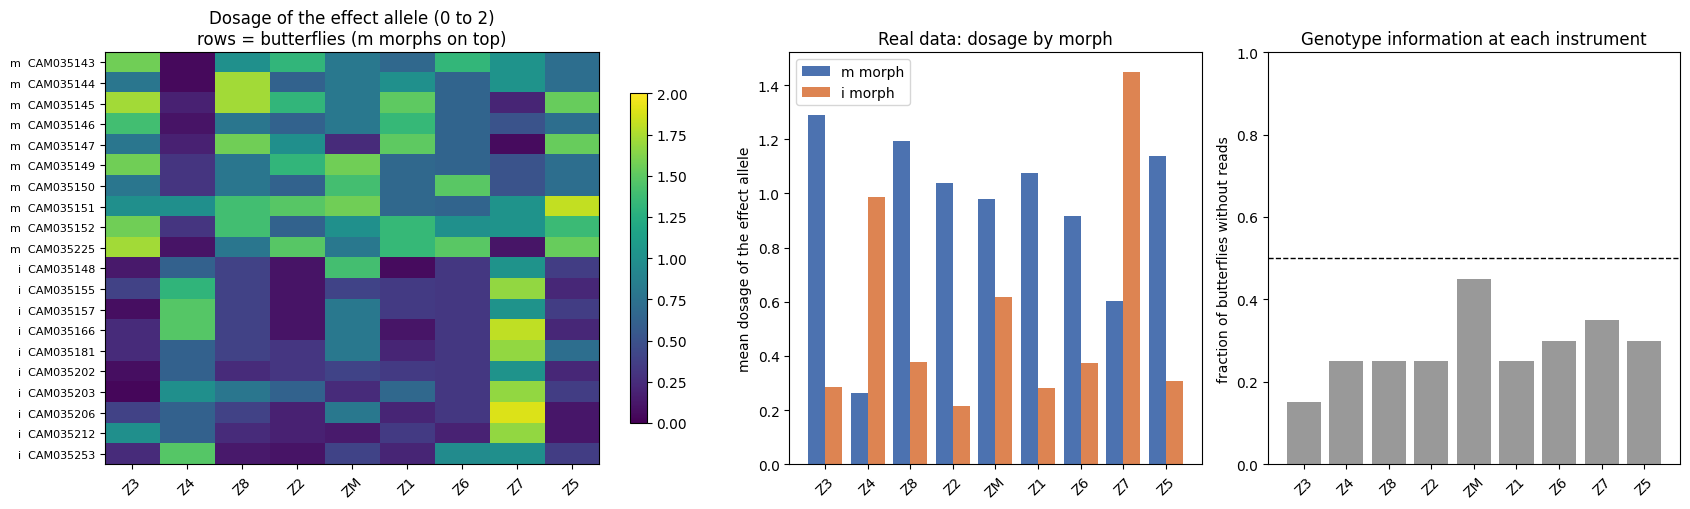

In [22]:
# ---- figure: dosages of the 20 butterflies at the instruments, sorted by morph
order = np.argsort(pheno.morph.values == "i", kind="stable")                 # m morphs first
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
im = ax[0].imshow(Zdf.values[order], aspect="auto", cmap="viridis", vmin=0, vmax=2)
ax[0].set_xticks(range(len(keep))); ax[0].set_xticklabels(keep, rotation=45)
ax[0].set_yticks(range(len(order))); ax[0].set_yticklabels([f"{pheno.morph.values[i]}  {pheno.sampleID.values[i]}" for i in order], fontsize=8)
ax[0].set_title("Dosage of the effect allele (0 to 2)\nrows = butterflies (m morphs on top)"); plt.colorbar(im, ax=ax[0], shrink=0.8)
mm = Zdf[pheno.morph.values == "m"].mean(); mi = Zdf[pheno.morph.values == "i"].mean()
xx = np.arange(len(keep))
ax[1].bar(xx - 0.2, mm, 0.4, label="m morph", color="#4c72b0"); ax[1].bar(xx + 0.2, mi, 0.4, label="i morph", color="#dd8452")
ax[1].set_xticks(xx); ax[1].set_xticklabels(keep, rotation=45); ax[1].set_ylabel("mean dosage of the effect allele"); ax[1].legend()
ax[1].set_title("Real data: dosage by morph")
ax[2].bar(xx, site_qc.loc[keep, "fraction without reads"], color="#999999")
ax[2].set_xticks(xx); ax[2].set_xticklabels(keep, rotation=45); ax[2].set_ylim(0, 1); ax[2].axhline(MAX_UNINFORMATIVE, color="k", ls="--", lw=1)
ax[2].set_ylabel("fraction of butterflies without reads"); ax[2].set_title("Genotype information at each instrument")
plt.tight_layout(); savefig("instrument_dosages"); plt.show()

### 4.4 A first look at the *real* first stage (and why it is not trustworthy)

Instrument **relevance** means: Z must predict X. For the **real morph** we can check it right now by regressing the morph (1 = *m*) on each dosage in the 20 butterflies and computing the **first-stage *F*-statistic**, $F=\dfrac{r^2}{1-r^2}(n-2)$ for one instrument.

Two warnings before you read the table:

* The top hits were **chosen because** they were associated with the morph **in these same butterflies**. Testing them again in the same individuals is circular: the *F* is **inflated by the winner's curse**. Honest relevance must be checked in an **independent** sample.
* With 20 individuals even a genuine instrument has a very noisy *F*.

In [23]:
rows_fs = []
for c in keep:
    r_, pv = stats.pearsonr(Zdf[c].values, pheno.x_morph.values)
    n_ = len(pheno); F = r_ ** 2 / (1 - r_ ** 2) * (n_ - 2) if abs(r_) < 1 else np.inf
    rows_fs.append(dict(id=c, role=inst_f.set_index("id").loc[c, "role"], r_with_morph=r_, R2=r_ ** 2, F_first_stage=F, P=pv,
                        mean_dose_m=Zdf.loc[pheno.morph.values == "m", c].mean(), mean_dose_i=Zdf.loc[pheno.morph.values == "i", c].mean()))
fs = pd.DataFrame(rows_fs).set_index("id")
display(fs.style.format({"r_with_morph": "{:.2f}", "R2": "{:.2f}", "F_first_stage": "{:.1f}", "P": "{:.1e}", "mean_dose_m": "{:.2f}", "mean_dose_i": "{:.2f}"}))
print("Rule of thumb: F > 10 for a strong instrument.  But remember: these variants were SELECTED in these same 20 butterflies,")
print("so the F values above are optimistic (winner's curse). They are NOT evidence that the variants cause the morph.")

,role,r_with_morph,R2,F_first_stage,P,mean_dose_m,mean_dose_i
id,,,,,,,
Z3,top hit,0.84,0.70,42.0,4.3e-06,1.29,0.29
Z4,top hit,-0.74,0.55,21.6,2.0e-04,0.26,0.99
Z8,top hit,0.81,0.66,34.5,1.5e-05,1.19,0.38
Z2,top hit,0.83,0.69,39.8,6.0e-06,1.04,0.21
ZM,M-locus control,0.43,0.19,4.1,5.7e-02,0.98,0.62
Z1,top hit,0.82,0.68,38.1,7.9e-06,1.07,0.28
Z6,top hit,0.68,0.47,15.9,8.6e-04,0.92,0.37
Z7,top hit,-0.75,0.57,23.9,1.2e-04,0.60,1.45
Z5,top hit,0.79,0.62,29.5,3.7e-05,1.14,0.31


Rule of thumb: F > 10 for a strong instrument.  But remember: these variants were SELECTED in these same 20 butterflies,
so the F values above are optimistic (winner's curse). They are NOT evidence that the variants cause the morph.


## 5. Hand Over to R

From here on we work in **R**. The cell `%load_ext rpy2.ipython` makes every cell that starts with the line `%%R` run as R code inside the same Colab session. R variables **persist between `%%R` cells**, just like Python variables.

Data go from Python to R through the two small tables written on Google Drive; the folder path travels in the environment variable `MR_DIR` (set in Section 2) and R reads it with `Sys.getenv("MR_DIR")`.

In [ ]:
%load_ext rpy2.ipython

In [24]:
%%R
# Our first R cell. Lines starting with '#' are comments. Everything after '%%R' above is R code.
cat(R.version.string, "\n")
suppressPackageStartupMessages({
  library(ivreg)      # ivreg(): two-stage least squares with proper standard errors and diagnostics
  library(sandwich)   # robust variance estimators (used by ivreg diagnostics)
  library(lmtest)     # coeftest() and friends
})
cat("ivreg version:", as.character(packageVersion("ivreg")), "\n")
cat("MR_DIR       :", Sys.getenv("MR_DIR"), "\n")

R version 4.5.3 (2026-03-11) 
ivreg version: 0.6.8 
MR_DIR       : /content/drive/MyDrive/GWAS/mendelian_randomization_HypMis/tables 


## 6. Instrumental-Variable Analysis in R

### 6.1 Read the tables and look at the instruments

R reads the two tables written in Section 4. `read.delim()` reads a tab-separated file into a **data frame** (R's table type). We tell it explicitly that `chr`, `EA` and `NEA` are **text**: otherwise R would read a column that contains only the allele letters `T`/`F` as TRUE/FALSE.

In [25]:
%%R
mr_dir <- Sys.getenv("MR_DIR")                                          # folder on Google Drive (set in Python)
geno <- read.delim(file.path(mr_dir, "genotypes_dosage.tsv"), stringsAsFactors = FALSE)
inst <- read.delim(file.path(mr_dir, "instruments.tsv"), stringsAsFactors = FALSE,
                   colClasses = c(chr = "character", EA = "character", NEA = "character"))
cat("butterflies:", nrow(geno), "   instruments:", nrow(inst), "\n\n")
print(inst[, c("id", "role", "chr", "pos", "EA", "NEA", "P_FE")])

zcols  <- inst$id[inst$role == "top hit"]               # the top variants of the meta-analysis: instruments Z1, Z2, ...
zm_col <- inst$id[inst$role == "M-locus control"]       # the positive control (character(0) if there is none)
K <- length(zcols)
cat("\ntop-hit instruments used in Sections 6 to 8:", zcols, "\n")
cat("M-locus control instrument (Section 9)      :", if (length(zm_col) > 0) zm_col else "none", "\n")

# Standardise each instrument to mean 0 and standard deviation 1 (so that all instruments have the same scale).
Zs <- scale(as.matrix(geno[, zcols]))
cat("\ncorrelation between the instruments (should be small: they are on different chromosomes):\n")
print(round(cor(Zs), 2))

butterflies: 20    instruments: 9 

  id            role chr      pos EA NEA         P_FE
1 Z1         top hit  28 14726976  A   C 6.093698e-05
2 Z2         top hit  26  4643718  A   G 6.162395e-05
3 Z3         top hit  13  9174425  A   C 6.489389e-05
4 Z4         top hit  19  8668136  G   A 7.112971e-05
5 Z5         top hit   5  2290681  C   A 9.487519e-05
6 Z6         top hit  32  4255228  T   A 1.116854e-04
7 Z7         top hit  32  7797921  C   T 1.143674e-04
8 Z8         top hit  24 15359794  T   G 1.153516e-04
9 ZM M-locus control  26  6737412  G   A 4.339790e-02

top-hit instruments used in Sections 6 to 8: Z1 Z2 Z3 Z4 Z5 Z6 Z7 Z8 
M-locus control instrument (Section 9)      : ZM 

correlation between the instruments (should be small: they are on different chromosomes):
      Z1    Z2    Z3    Z4    Z5    Z6    Z7    Z8
Z1  1.00  0.68  0.74 -0.68  0.77  0.47 -0.74  0.81
Z2  0.68  1.00  0.78 -0.59  0.81  0.57 -0.66  0.69
Z3  0.74  0.78  1.00 -0.70  0.65  0.60 -0.60  0.58
Z4 -0.68

### 6.2 The simulation design: confounder C, exposure X and outcome Y

We now **simulate** the unmeasured part of the story on top of the **real genotypes**. For each of the 20 butterflies:

$$\begin{aligned}
C_i &\sim N(0,1) &&\text{habitat (unmeasured confounder), drawn independently of the genotypes}\\
X_i &= \textstyle\sum_j \pi_j\,Z_{ij} + \delta\,C_i + \varepsilon_{X,i} &&\text{wing-colour score: genes } + \text{ habitat } + \text{ noise}\\
Y_i &= \beta\,X_i + \gamma\,C_i + \varepsilon_{Y,i} &&\text{fitness index: colour } + \text{ habitat } + \text{ noise}
\end{aligned}$$

with $Z_{ij}$ the standardised dosage of instrument $j$. The **parameters** and what they mean:

| Parameter | Value | Meaning |
|---|---|---|
| $\beta$ = `BETA` | 2 | the **true causal effect** of colour on fitness: **the number we want to recover** |
| $\gamma$ = `GAMMA` | 5 | effect of habitat on fitness (strong confounding) |
| $\delta$ = `DELTA` | 1.5 | effect of habitat on colour |
| `VAR_G` | 4 | variance of X explained by the genes in total (**instrument strength**); each of the K instruments contributes $\pi_j=\sqrt{\text{VAR\_G}/K}$ |
| `SD_EX`, `SD_EY` | 0.5, 1 | residual noise in X and Y |

**What to expect from theory.** The naive slope of Y on X converges to

$$\beta+\frac{\gamma\,\delta}{\mathrm{Var}(X)},\qquad \mathrm{Var}(X)=\text{VAR\_G}+\delta^2+\text{SD\_EX}^2,$$

i.e. **more than 2**: the confounder inflates the apparent effect. The instrumental-variable estimate converges to **$\beta=2$**. The cell below prints the theoretical value of the naive slope.

The causal diagram of the simulation:

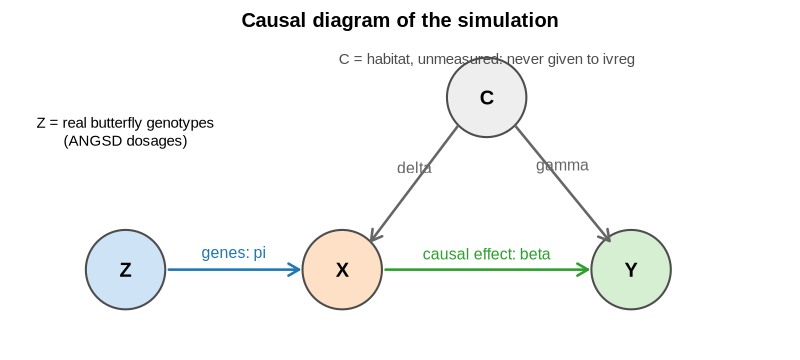

In [26]:
%%R -w 8 -h 3.6 -u in -r 100
# Draw the causal diagram with base R graphics (no extra package needed).
par(mar = c(0.5, 0.5, 2, 0.5))
plot(NA, xlim = c(0, 10), ylim = c(0, 5), axes = FALSE, xlab = "", ylab = "", main = "Causal diagram of the simulation")
node <- function(x, y, lab, col) { symbols(x, y, circles = 0.55, inches = FALSE, add = TRUE, bg = col, fg = "grey30", lwd = 2); text(x, y, lab, font = 2, cex = 1.2) }
arr  <- function(x0, y0, x1, y1, lab = "", col = "black", lty = 1) { arrows(x0, y0, x1, y1, length = 0.12, lwd = 2.5, col = col, lty = lty)
                                                                     text((x0 + x1) / 2, (y0 + y1) / 2 + 0.28, lab, cex = 0.95, col = col) }
node(1.2, 1.2, "Z", "#cfe3f7"); node(4.2, 1.2, "X", "#fde0c5"); node(8.2, 1.2, "Y", "#d6efd2"); node(6.2, 4.2, "C", "#eeeeee")
arr(1.8, 1.2, 3.6, 1.2, "genes: pi", "#1f77b4")
arr(4.8, 1.2, 7.6, 1.2, "causal effect: beta", "#2ca02c")
arr(5.8, 3.7, 4.6, 1.7, "delta", "grey40"); arr(6.6, 3.7, 7.9, 1.7, "gamma", "grey40")
text(1.2, 3.6, "Z = real butterfly genotypes\n(ANGSD dosages)", cex = 0.9)
text(6.2, 4.85, "C = habitat, unmeasured: never given to ivreg", cex = 0.9, col = "grey30")

In [27]:
%%R
# ------------------------------------------------------------------ simulation parameters (edit and re-run to explore)
SEED  <- 2026     # makes the "random" draws reproducible
BETA  <- 2        # TRUE causal effect of X on Y
GAMMA <- 5        # effect of the confounder C on Y
DELTA <- 1.5      # effect of the confounder C on X
VAR_G <- 4        # variance of X explained by the genetic score
SD_EX <- 0.5      # residual noise in X
SD_EY <- 1        # residual noise in Y
PI    <- rep(sqrt(VAR_G / K), K)      # first-stage effect of each standardised instrument on X

varX <- VAR_G + DELTA^2 + SD_EX^2
cat("Var(X)                              =", varX, "\n")
cat("TRUE causal effect (beta)           =", BETA, "\n")
cat("Naive regression will converge to   =", BETA + GAMMA * DELTA / varX, " (beta + gamma*delta/Var(X))\n")
cat("Share of Var(X) due to the genes    =", round(VAR_G / varX, 2), "\n")

Var(X)                              = 6.5 
TRUE causal effect (beta)           = 2 
Naive regression will converge to   = 3.153846  (beta + gamma*delta/Var(X))
Share of Var(X) due to the genes    = 0.62 


### 6.3 A function that simulates one data set

R **functions** are defined with `function(arguments) { ... }`. This one draws C, then X, then Y, exactly as in the equations above, and returns a data frame with the true C kept for later (we will use it only to show what an omniscient analyst would see).

Two extra arguments let us **break the assumptions** later (Section 6.10): `direct` adds a **direct effect of the genotypes on Y** (pleiotropy), and `zc` makes the **habitat correlated with the genotypes** (a confounded instrument). With the defaults (`0`) all three IV assumptions hold.

`rnorm(n)` draws n random numbers from a standard normal distribution; `Zs %*% PI` is a matrix product, i.e. $\sum_j\pi_jZ_{ij}$ for every butterfly; `rowSums(Zs)` is the simple **allele score** (sum of the standardised dosages).

In [28]:
%%R
simulate_data <- function(Zs, beta = BETA, PI = rep(sqrt(VAR_G / ncol(Zs)), ncol(Zs)), delta = DELTA, gamma = GAMMA,
                          sx = SD_EX, sy = SD_EY, direct = rep(0, ncol(Zs)), zc = 0, seed = NULL) {
  if (!is.null(seed)) set.seed(seed)
  n <- nrow(Zs)
  g <- as.numeric(Zs %*% PI)                                  # genetic part of the exposure
  C <- rnorm(n) + zc * g / sd(g)                              # habitat (zc = 0: independent of the genotypes)
  X <- g + delta * C + rnorm(n, 0, sx)                        # exposure: wing-colour score
  Y <- beta * X + gamma * C + as.numeric(Zs %*% direct) + rnorm(n, 0, sy)   # outcome: fitness index
  data.frame(Zs, X = X, Y = Y, C = C, G = g, S = rowSums(Zs)) # Zs columns first, then X, Y, C, genetic part G, allele score S
}

d <- simulate_data(Zs, seed = SEED)
cat("one simulated data set (first 6 butterflies):\n")
print(round(head(d[, c(zcols[1:min(3, K)], "X", "Y", "C", "S")]), 2))
cat("\ncorrelation of the habitat C with each instrument (should be near 0: C is independent of Z):\n")
print(round(cor(d$C, Zs), 2))
cat("(with only 20 butterflies the sample correlations are not exactly 0; in the population they are)\n")

one simulated data set (first 6 butterflies):
     Z1    Z2    Z3     X      Y     C     S
1  0.00  1.34  1.26  3.13   7.71  0.52  3.56
2  0.65  0.00  0.00 -0.76  -6.14 -1.08  1.33
3  1.68  1.34  1.52  3.44   6.37  0.14  5.55
4  1.34  0.00  0.98  0.88   1.65 -0.08  0.39
5  1.68  0.73  0.00  1.04  -2.08 -0.67  2.86
6 -1.25 -1.03 -1.05 -6.75 -24.66 -2.52 -5.55

correlation of the habitat C with each instrument (should be near 0: C is independent of Z):
       Z1   Z2   Z3   Z4   Z5   Z6  Z7   Z8
[1,] 0.07 0.14 0.14 0.19 0.03 0.04 0.3 0.07
(with only 20 butterflies the sample correlations are not exactly 0; in the population they are)


### 6.4 Step 1: the naive regression `Y ~ X` is biased

`lm(Y ~ X, data = d)` fits an ordinary least-squares line. `summary()` prints the estimate, its standard error, *t*-value and P-value. Look at the row `X`: its estimate is the naive "effect of colour on fitness".

In [29]:
%%R
ols <- lm(Y ~ X, data = d)                    # naive regression: the habitat C is not in the model
print(summary(ols)$coefficients)
cat("\nTRUE causal effect:", BETA, "\n")
cat("Naive OLS estimate:", round(coef(ols)["X"], 2), "  95% CI:", round(confint(ols)["X", ], 2), "\n")
cat("-> the confidence interval", if (BETA >= confint(ols)["X", 1] && BETA <= confint(ols)["X", 2]) "happens to contain" else "does NOT contain",
    "the truth in this draw (with 20 butterflies noise can hide the bias; Section 6.8 repeats the experiment 2000 times).\n")

             Estimate Std. Error   t value     Pr(>|t|)
(Intercept) -1.831161  0.7977782 -2.295326 3.394767e-02
X            2.882758  0.2445836 11.786393 6.734866e-10

TRUE causal effect: 2 
Naive OLS estimate: 2.88   95% CI: 2.37 3.4 
-> the confidence interval does NOT contain the truth in this draw (with 20 butterflies noise can hide the bias; Section 6.8 repeats the experiment 2000 times).


### 6.5 Step 2: an omniscient analyst who *can* see the confounder

Because **we** simulated the habitat, we can add it to the regression, `lm(Y ~ X + C)`. This is the **gold standard that is impossible in real data**, where C is unmeasured. It shows that the bias in Step 1 is caused by the omitted confounder and nothing else.

In [30]:
%%R
oracle <- lm(Y ~ X + C, data = d)             # only possible in a simulation: C is known to us
print(summary(oracle)$coefficients)
cat("\nOracle estimate of beta:", round(coef(oracle)["X"], 2), "  95% CI:", round(confint(oracle)["X", ], 2), "  (truth:", BETA, ")\n")

             Estimate Std. Error   t value     Pr(>|t|)
(Intercept) -0.434032  0.1783804 -2.433182 2.629705e-02
X            2.104239  0.0634769 33.149685 6.875573e-17
C            4.411130  0.2186675 20.172774 2.600103e-13

Oracle estimate of beta: 2.1   95% CI: 1.97 2.24   (truth: 2 )


### 6.6 Step 3: two-stage least squares, first by hand

Now the real task: estimate $\beta$ **without C**, using only the genotypes. We start with the allele score `S` as the single instrument (the sum of the eight standardised dosages) and carry out the two stages manually.

* **Stage 1:** `lm(X ~ S)`. Its *F*-statistic tells us whether the instrument is **relevant**. We keep the fitted values `X_hat`, "the part of the colour that is explained by genes".
* **Stage 2:** `lm(Y ~ X_hat)`. The slope on `X_hat` is the 2SLS estimate.

For a single instrument this equals the **Wald ratio** $\mathrm{Cov}(S,Y)/\mathrm{Cov}(S,X)$, which we also compute.

> **Warning.** The *standard error* printed by the second `lm` is **wrong** (it treats `X_hat` as if it had been measured instead of estimated, and uses the wrong residuals). Only the **point estimate** is valid. `ivreg` below gives correct standard errors.

In [31]:
%%R
# ---- stage 1: regress the exposure on the instrument
stage1 <- lm(X ~ S, data = d)
fstat  <- summary(stage1)$fstatistic
cat("STAGE 1 (X ~ S):  R-squared =", round(summary(stage1)$r.squared, 3),
    "  F =", round(fstat["value"], 1), " on", fstat["numdf"], "and", fstat["dendf"], "df\n")
d$X_hat <- fitted(stage1)                       # the genetically predicted exposure

# ---- stage 2: regress the outcome on the PREDICTED exposure
stage2 <- lm(Y ~ X_hat, data = d)
cat("STAGE 2 (Y ~ X_hat): slope =", round(coef(stage2)["X_hat"], 3), "   <- the 2SLS estimate (its standard error here is wrong)\n")

# ---- the same number as a ratio of covariances (Wald ratio)
wald <- cov(d$S, d$Y) / cov(d$S, d$X)
cat("Wald ratio Cov(S,Y)/Cov(S,X) =", round(wald, 3), "   <- identical, because there is a single instrument\n")
cat("TRUE causal effect           =", BETA, "     naive OLS =", round(coef(ols)["X"], 3), "\n")

STAGE 1 (X ~ S):  R-squared = 0.836   F = 91.7  on 1 and 18 df
STAGE 2 (Y ~ X_hat): slope = 2.445    <- the 2SLS estimate (its standard error here is wrong)
Wald ratio Cov(S,Y)/Cov(S,X) = 2.445    <- identical, because there is a single instrument
TRUE causal effect           = 2      naive OLS = 2.883 


### 6.7 Step 4: `ivreg`, the correct way

`ivreg(Y ~ X | S, data = d)` reads: *"outcome `Y`, regressed on the exposure `X`, **instrumented by** `S`"*. Everything **before** the `|` is the second-stage model; everything **after** it is the list of **instruments** (variables that appear only in the first stage). Exogenous controls (none here) would appear on both sides.

`summary(fit, diagnostics = TRUE)` adds three tests:

| Diagnostic | Null hypothesis | What to hope for |
|---|---|---|
| **Weak instruments** | the instruments do not predict X (the first-stage *F*) | **small P** (reject: the instruments are relevant). Compare the statistic with 10. |
| **Wu-Hausman** | OLS and IV estimates are equal, i.e. X is exogenous | a small P says **OLS is inconsistent: there is confounding** and IV is needed |
| **Sargan** (only with more instruments than exposures) | all instruments are valid (no direct effect on Y) | a **large** P (no evidence of invalid instruments) |

In [32]:
%%R
iv_score <- ivreg(Y ~ X | S, data = d)          # one instrument: the allele score
print(summary(iv_score, diagnostics = TRUE))


Call:
ivreg(formula = Y ~ X | S, data = d)

Residuals:
     Min       1Q   Median       3Q      Max 
-8.05391 -2.34801 -0.04048  2.13653  7.61729 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  -2.0216     0.8674  -2.331   0.0316 *  
X             2.4449     0.2904   8.420 1.17e-07 ***

Diagnostic tests:
                 df1 df2 statistic  p-value    
Weak instruments   1  18     91.67 1.74e-08 ***
Wu-Hausman         1  17    165.14 3.50e-10 ***
Sargan             0  NA        NA       NA    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 3.838 on 18 degrees of freedom
Multiple R-Squared: 0.8649,	Adjusted R-squared: 0.8574 
Wald test:  70.9 on 1 and 18 DF,  p-value: 1.173e-07 



**How to read this output.** The `Coefficients` row `X` is $\hat\beta_{IV}$ with a *correct* standard error. Compare it with the true value (2) and with the naive estimate (Step 1). Under `Diagnostic tests`, check that the *weak-instruments* statistic is well above 10 and that the *Wu-Hausman* test flags the confounding. (With only 20 butterflies the Wu-Hausman test has little power, so it may or may not reject.)

Next we verify that our **hand-made 2SLS function** gives exactly the same estimate and standard error as `ivreg`. We will reuse this function thousands of times in the simulations (it is much faster than calling `ivreg`).

In [33]:
%%R
# Fast two-stage least squares for ONE exposure x and one or several instruments (columns of Zmat).
# Returns the estimate, its standard error and the first-stage F statistic.
tsls_fit <- function(y, x, Zmat) {
  Zmat <- as.matrix(Zmat); n <- length(y); k <- ncol(Zmat)
  st1  <- lm(x ~ Zmat)                                    # stage 1
  xhat <- fitted(st1)
  sxx  <- sum((xhat - mean(xhat))^2)
  b    <- sum((xhat - mean(xhat)) * (y - mean(y))) / sxx  # stage 2 slope
  a    <- mean(y) - b * mean(x)
  s2   <- sum((y - a - b * x)^2) / (n - 2)                # residuals use the REAL x, not x_hat (this is the correction)
  r2   <- summary(st1)$r.squared
  c(beta = b, se = sqrt(s2 / sxx), F = (r2 / k) / ((1 - r2) / (n - k - 1)))
}
# Fast ordinary least squares slope of y on x.
ols_fit <- function(y, x) {
  n <- length(y); sxx <- sum((x - mean(x))^2); b <- sum((x - mean(x)) * (y - mean(y))) / sxx
  a <- mean(y) - b * mean(x); c(beta = b, se = sqrt(sum((y - a - b * x)^2) / (n - 2) / sxx))
}

mine <- tsls_fit(d$Y, d$X, d$S)
cs   <- summary(iv_score)$coefficients["X", ]
cat("our tsls_fit :  beta =", round(mine["beta"], 4), "  se =", round(mine["se"], 4), "  first-stage F =", round(mine["F"], 2), "\n")
cat("ivreg        :  beta =", round(cs["Estimate"], 4), "  se =", round(cs["Std. Error"], 4), "\n")
cat("identical:", isTRUE(all.equal(unname(mine["beta"]), unname(cs["Estimate"]))) && isTRUE(all.equal(unname(mine["se"]), unname(cs["Std. Error"]))), "\n")

our tsls_fit :  beta = 2.4449   se = 0.2904   first-stage F = 91.67 
ivreg        :  beta = 2.4449   se = 0.2904 
identical: TRUE 


### 6.8 Four ways to use the same genotypes

So far the instrument was the allele score. Real analyses make several choices, and they matter, especially with only 20 butterflies:

| Instrument choice | R formula | Degrees of freedom of the first stage |
|---|---|---|
| **A. the single best SNP** (Z1, the top hit) | `ivreg(Y ~ X \| Z1)` | 1 (but this SNP explains only 1/K of the genetic variance: **weak**) |
| **B. all K SNPs as separate instruments** | `ivreg(Y ~ X \| Z1 + Z2 + ...)` | K (**over-fitting** risk with n = 20) |
| **C. the allele score** | `ivreg(Y ~ X \| S)` | 1 (**strong** and not over-fitted) |
| naive | `lm(Y ~ X)` | not an IV method |

The code builds the formulas with `paste()` and `as.formula()` so that it works for any number of instruments, then collects estimates and 95 % confidence intervals in a table and a plot.

                            method estimate     se   lo   hi F_first_stage
1                 naive OLS: Y ~ X     2.88 0.2446 2.37 3.40            NA
2 oracle OLS: Y ~ X + C (needs C!)     2.10 0.0635 1.97 2.24            NA
3                IV: single SNP Z1     2.18 0.4264 1.29 3.08          16.5
4        IV: all 8 SNPs separately     2.70 0.2583 2.16 3.25          16.7
5                 IV: allele score     2.44 0.2904 1.83 3.05          91.7


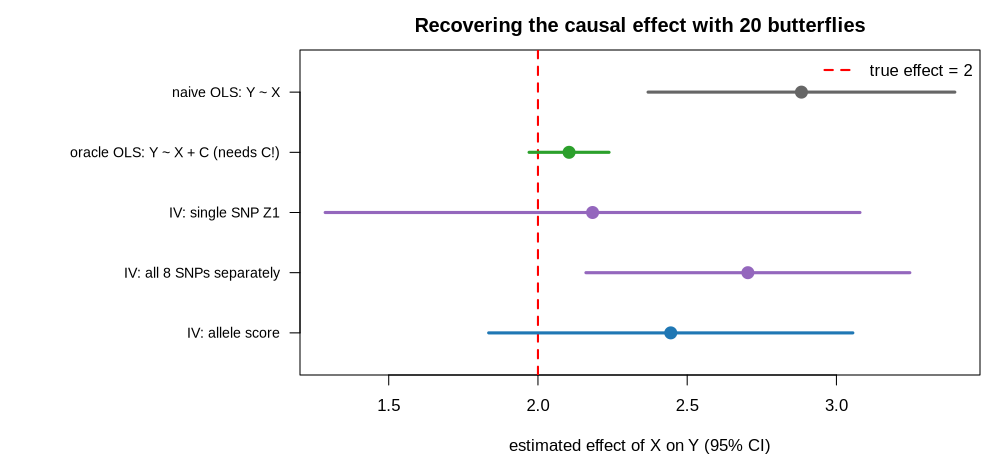

In [34]:
%%R -w 10 -h 4.6 -u in -r 100
f_snp1 <- as.formula(paste("Y ~ X |", zcols[1]))                     # A: the single top SNP
f_all  <- as.formula(paste("Y ~ X |", paste(zcols, collapse = " + ")))   # B: all SNPs as separate instruments
iv_snp1 <- ivreg(f_snp1, data = d)
iv_all  <- ivreg(f_all,  data = d)

ci_row <- function(fit, label, term = "X") {                          # estimate, SE and 95% CI of the coefficient 'term'
  cf <- summary(fit)$coefficients[term, ]; dfr <- df.residual(fit); tq <- qt(0.975, dfr)
  data.frame(method = label, estimate = unname(cf["Estimate"]), se = unname(cf["Std. Error"]),
             lo = unname(cf["Estimate"] - tq * cf["Std. Error"]), hi = unname(cf["Estimate"] + tq * cf["Std. Error"]))
}
tab <- rbind(ci_row(ols,      "naive OLS: Y ~ X"),
             ci_row(oracle,   "oracle OLS: Y ~ X + C (needs C!)"),
             ci_row(iv_snp1,  paste0("IV: single SNP ", zcols[1])),
             ci_row(iv_all,   paste0("IV: all ", K, " SNPs separately")),
             ci_row(iv_score, "IV: allele score"))
tab$F_first_stage <- c(NA, NA, tsls_fit(d$Y, d$X, d[[zcols[1]]])["F"], tsls_fit(d$Y, d$X, d[, zcols])["F"], tsls_fit(d$Y, d$X, d$S)["F"])
rownames(tab) <- NULL
print(format(tab, digits = 3))

par(mar = c(4.2, 15, 2.5, 1))
yy <- rev(seq_len(nrow(tab)))
plot(NA, xlim = range(c(tab$lo, tab$hi, BETA)), ylim = c(0.5, nrow(tab) + 0.5), yaxt = "n", ylab = "", xlab = "estimated effect of X on Y (95% CI)",
     main = "Recovering the causal effect with 20 butterflies")
abline(v = BETA, lty = 2, col = "red", lwd = 2)
segments(tab$lo, yy, tab$hi, yy, lwd = 3, col = c("grey40", "#2ca02c", "#9467bd", "#9467bd", "#1f77b4"))
points(tab$estimate, yy, pch = 19, cex = 1.6, col = c("grey40", "#2ca02c", "#9467bd", "#9467bd", "#1f77b4"))
axis(2, at = yy, labels = tab$method, las = 1, cex.axis = 0.85)
legend("topright", legend = paste("true effect =", BETA), lty = 2, col = "red", lwd = 2, bty = "n")
d_tab <- tab   # keep for the final summary

**What to look for.**

* The **naive** regression is pulled **above** the truth by the confounder (how far depends on the random draw).
* The **oracle** regression is centred on the truth but is impossible with real data.
* **The single SNP** is a weak instrument (small first-stage *F*): wide, unstable interval.
* **All SNPs separately** over-fit stage 1 (K = 8 instruments and 20 butterflies), so the estimate drifts **towards the naive OLS value**.
* **The allele score** (one strong instrument) is the best compromise: centred near the truth, with an honest interval.

One random draw cannot prove any of this, because with 20 butterflies the noise is large. The next sections repeat the experiment thousands of times.

### 6.9 Repeat the experiment 2000 times

A single data set of 20 butterflies cannot show whether a method is **biased**, because random noise can hide (or fake) a bias. Statisticians therefore use a **Monte Carlo experiment**: simulate the study **many times** with the *same* real genotypes, new habitat C and new noise each time, apply every method to every replicate, and look at the **distribution** of the estimates. Because we know the truth ($\beta=2$), we can measure for each method

* **bias**: median estimate minus the truth;
* **spread**: standard deviation and inter-quartile range (IQR);
* **coverage**: the fraction of replicates in which the 95 % confidence interval contains the truth (should be about 95 %);
* the typical **first-stage *F***.

`mc_run()` below does one replicate per loop iteration, using the fast functions from Section 6.7. We report the **median** rather than the mean because a weak instrument produces occasional extreme values that make the mean meaningless.

In [35]:
%%R
# One Monte Carlo experiment: 'reps' simulated studies. Zfun() must return the (standardised) genotype matrix of one study.
mc_run <- function(Zfun, reps, var_g = VAR_G, beta = BETA, delta = DELTA, gamma = GAMMA, sx = SD_EX, sy = SD_EY,
                   direct_scale = 0, zc = 0, seed = 1) {
  set.seed(seed)
  out <- matrix(NA_real_, reps, 11)
  colnames(out) <- c("ols", "ols_se", "iv1", "iv1_se", "iv1_F", "ivk", "ivk_se", "ivk_F", "ivs", "ivs_se", "ivs_F")
  for (r in seq_len(reps)) {
    Z   <- Zfun(); k <- ncol(Z); PIr <- rep(sqrt(var_g / k), k)
    dd  <- simulate_data(Z, beta = beta, PI = PIr, delta = delta, gamma = gamma, sx = sx, sy = sy, direct = direct_scale * PIr, zc = zc)
    out[r, ] <- c(ols_fit(dd$Y, dd$X),                  # naive OLS (2 numbers)
                  tsls_fit(dd$Y, dd$X, Z[, 1]),         # IV with the single first SNP (3 numbers)
                  tsls_fit(dd$Y, dd$X, Z),              # IV with all SNPs separately (3 numbers)
                  tsls_fit(dd$Y, dd$X, rowSums(Z)))     # IV with the allele score (3 numbers)
  }
  out
}

# Summarise a Monte Carlo experiment: one row per method.
mc_summary <- function(out, beta = BETA) {
  one <- function(lab, est, se, Fv = NULL)
    data.frame(method = lab, median_est = median(est), mean_est = mean(est), sd = sd(est), q25 = unname(quantile(est, 0.25)), q75 = unname(quantile(est, 0.75)),
               bias_median = median(est) - beta, coverage_95 = mean(abs(est - beta) <= 1.96 * se, na.rm = TRUE), median_F = if (is.null(Fv)) NA else median(Fv))
  rbind(one("naive OLS",       out[, "ols"], out[, "ols_se"]),
        one("IV single SNP",   out[, "iv1"], out[, "iv1_se"], out[, "iv1_F"]),
        one("IV all SNPs",     out[, "ivk"], out[, "ivk_se"], out[, "ivk_F"]),
        one("IV allele score", out[, "ivs"], out[, "ivs_se"], out[, "ivs_F"]))
}

mc <- mc_run(function() Zs, reps = 2000, seed = SEED + 1)          # the real 20 genotypes, 2000 new "worlds"
mc_tab <- mc_summary(mc)
print(format(mc_tab[, c("method", "median_est", "sd", "bias_median", "coverage_95", "median_F")], digits = 3), row.names = FALSE)
cat("\nTRUE effect =", BETA, "\n")

          method median_est    sd bias_median coverage_95 median_F
       naive OLS       2.78 0.285     0.78076       0.362       NA
   IV single SNP       2.03 0.626     0.02685       0.934    18.39
     IV all SNPs       2.37 0.375     0.36850       0.784     7.94
 IV allele score       2.01 0.483     0.00773       0.930    55.40

TRUE effect = 2 


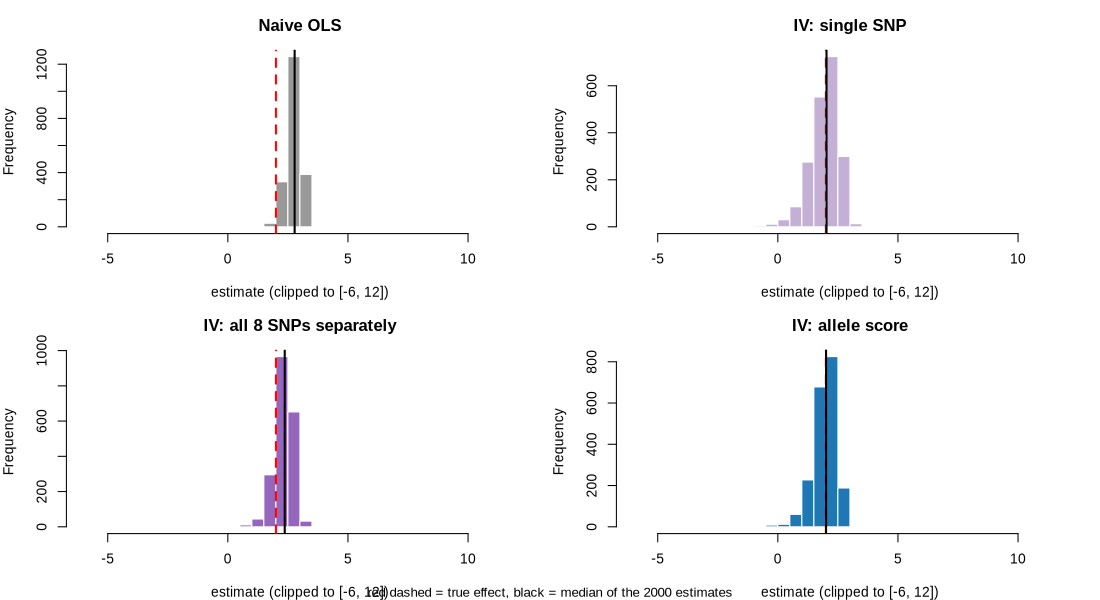

In [36]:
%%R -w 11 -h 6 -u in -r 100
clip <- function(x, lo = -6, hi = 12) pmin(pmax(x, lo), hi)           # extreme values are piled into the end bins so that the plot stays readable
cols <- c(ols = "grey60", iv1 = "#c5b0d5", ivk = "#9467bd", ivs = "#1f77b4")
ttl  <- c(ols = "Naive OLS", iv1 = "IV: single SNP", ivk = paste("IV: all", K, "SNPs separately"), ivs = "IV: allele score")
par(mfrow = c(2, 2), mar = c(4, 4, 3, 1))
for (m in names(cols)) {
  hist(clip(mc[, m]), breaks = seq(-6, 12, by = 0.5), col = cols[m], border = "white", main = ttl[m], xlab = "estimate (clipped to [-6, 12])")
  abline(v = BETA, col = "red", lty = 2, lwd = 2); abline(v = median(mc[, m]), col = "black", lwd = 2)
}
mtext("red dashed = true effect, black = median of the 2000 estimates", side = 1, outer = TRUE, line = -1, cex = 0.8)

**What the experiment shows.**

* **Naive OLS** is tightly clustered, but **around the wrong value**: more data would only make it more precise and still wrong (this is *confounding bias*).
* **Single SNP**: the distribution is wide and heavy-tailed. The first-stage *F* is far below 10 (weak instrument), so individual estimates are unreliable even though the *median* is near the truth.
* **All SNPs separately**: stage 1 over-fits 20 butterflies with 8 instruments, so the estimate is **shifted towards OLS**; its coverage is also poor.
* **Allele score**: centred near the truth with about the nominal coverage. Collapsing many weak variants into one score is the standard way to make a strong instrument.

### 6.10 Instrument strength: when does IV fail?

We vary `VAR_G`, the share of the exposure's variance explained by the genes, from almost nothing (0.05) to a lot (8), and repeat 500 experiments for each value. On the horizontal axis we plot the typical **first-stage *F*** (log scale). The classical result: **the weaker the instrument, the closer the IV estimate is to the biased OLS estimate**; above **F ≈ 10** the bias is small.

 VAR_G median_F_score median_F_all naive_OLS IV_allele_score IV_all_SNPs
  0.05          0.846         1.02      4.89            3.40        4.77
  0.10          1.339         1.11      4.79            2.78        4.54
  0.25          3.386         1.35      4.52            2.11        4.08
  0.50          6.948         1.78      4.18            1.95        3.59
  1.00         13.869         2.70      3.74            1.97        3.09
  2.00         27.673         4.42      3.22            1.98        2.61
  4.00         55.689         7.88      2.77            1.98        2.33
  8.00        110.604        15.01      2.44            1.99        2.18


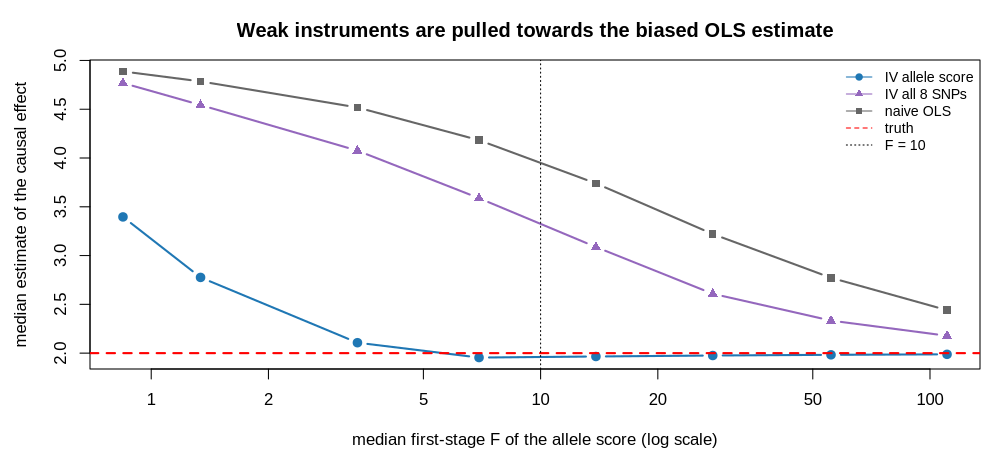

In [37]:
%%R -w 10 -h 4.6 -u in -r 100
vg_grid <- c(0.05, 0.1, 0.25, 0.5, 1, 2, 4, 8)
res_str <- do.call(rbind, lapply(vg_grid, function(v) {
  m <- mc_run(function() Zs, reps = 500, var_g = v, seed = SEED + 2)
  data.frame(VAR_G = v, median_F_score = median(m[, "ivs_F"]), median_F_all = median(m[, "ivk_F"]),
             naive_OLS = median(m[, "ols"]), IV_allele_score = median(m[, "ivs"]), IV_all_SNPs = median(m[, "ivk"]))
}))
print(format(res_str, digits = 3), row.names = FALSE)

par(mar = c(4.5, 4.5, 3, 1))
yl <- range(c(res_str$naive_OLS, res_str$IV_allele_score, res_str$IV_all_SNPs, BETA))
plot(res_str$median_F_score, res_str$IV_allele_score, log = "x", type = "b", pch = 19, col = "#1f77b4", lwd = 2, ylim = yl,
     xlab = "median first-stage F of the allele score (log scale)", ylab = "median estimate of the causal effect",
     main = "Weak instruments are pulled towards the biased OLS estimate")
lines(res_str$median_F_score, res_str$IV_all_SNPs, type = "b", pch = 17, col = "#9467bd", lwd = 2)
lines(res_str$median_F_score, res_str$naive_OLS,   type = "b", pch = 15, col = "grey40", lwd = 2)
abline(h = BETA, col = "red", lty = 2, lwd = 2); abline(v = 10, col = "black", lty = 3)
legend("topright", c("IV allele score", paste("IV all", K, "SNPs"), "naive OLS", "truth", "F = 10"), col = c("#1f77b4", "#9467bd", "grey40", "red", "black"),
       lty = c(1, 1, 1, 2, 3), pch = c(19, 17, 15, NA, NA), bty = "n", cex = 0.85)

### 6.11 What if we had more butterflies?

Everything so far used the 20 real genotypes. To see what happens with larger samples we create **virtual butterflies**: for each instrument we draw genotypes from a **binomial(2, p)** distribution with the allele frequency *p* observed in the real 20 butterflies (the Hardy-Weinberg assumption), standardise them, and run the same simulation. We vary the sample size N from 20 to 2000 and plot, for each N, the **median and the inter-quartile range** of the estimates.

* The IV estimate (allele score) **converges to the truth** and its spread shrinks with N (it is *consistent*).
* The naive OLS estimate also becomes more precise, but **converges to the wrong value**. Confounding is not a small-sample problem.

allele frequencies used for the virtual butterflies: 0.34 0.31 0.39 0.31 0.36 0.32 0.51 0.39 

    N          method median_est  q25  q75 coverage_95
   20       naive OLS       3.15 2.85 3.40       0.200
   20 IV allele score       2.04 1.67 2.37       0.920
   50       naive OLS       3.13 2.99 3.29       0.000
   50 IV allele score       2.02 1.75 2.19       0.947
  100       naive OLS       3.13 3.04 3.25       0.000
  100 IV allele score       1.99 1.81 2.14       0.947
  500       naive OLS       3.15 3.10 3.21       0.000
  500 IV allele score       2.02 1.92 2.09       0.950
 2000       naive OLS       3.15 3.13 3.17       0.000
 2000 IV allele score       2.00 1.97 2.04       0.953


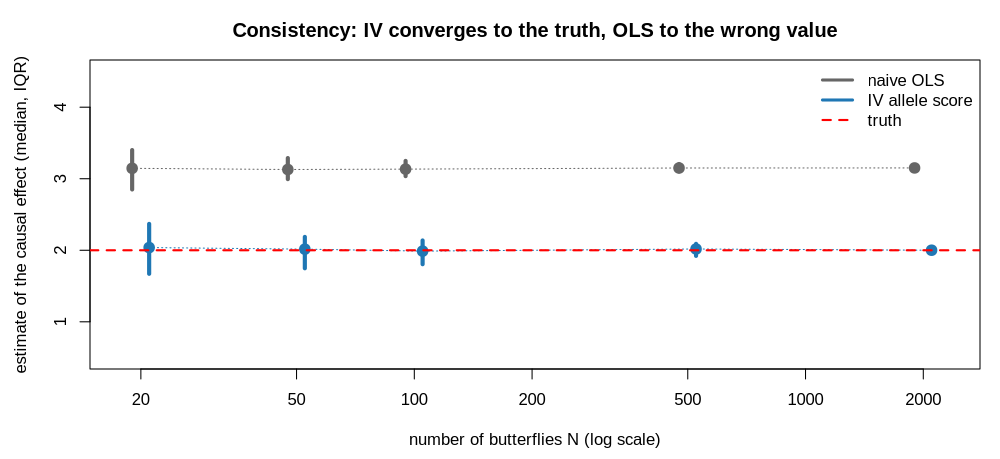

In [38]:
%%R -w 10 -h 4.6 -u in -r 100
freq <- pmin(pmax(colMeans(geno[, zcols]) / 2, 0.1), 0.9)             # allele frequencies of the real data (kept between 0.1 and 0.9)
virtual_Z <- function(N) {                                           # N virtual butterflies at the K instruments
  Z <- sapply(seq_len(K), function(j) rbinom(N, 2, freq[j]))         # genotype = number of effect alleles ~ Binomial(2, p)
  Z <- sweep(sweep(Z, 2, 2 * freq, "-"), 2, sqrt(2 * freq * (1 - freq)), "/")   # standardise with the theoretical mean and sd
  colnames(Z) <- zcols
  Z
}
cat("allele frequencies used for the virtual butterflies:", round(freq, 2), "\n\n")

n_grid <- c(20, 50, 100, 500, 2000)
res_n <- do.call(rbind, lapply(n_grid, function(N) {
  s <- mc_summary(mc_run(function() virtual_Z(N), reps = 300, seed = SEED + 3))
  data.frame(N = N, s[, c("method", "median_est", "q25", "q75", "coverage_95")])
}))
print(format(res_n[res_n$method %in% c("naive OLS", "IV allele score"), ], digits = 3), row.names = FALSE)

par(mar = c(4.5, 4.5, 3, 1))
plot(NA, log = "x", xlim = range(n_grid) * c(0.9, 1.15), ylim = c(BETA - 1.5, BETA + 2.5), xlab = "number of butterflies N (log scale)",
     ylab = "estimate of the causal effect (median, IQR)", main = "Consistency: IV converges to the truth, OLS to the wrong value")
for (nm in c("naive OLS", "IV allele score")) {
  r <- res_n[res_n$method == nm, ]; col <- c("naive OLS" = "grey40", "IV allele score" = "#1f77b4")[nm]; sh <- if (nm == "naive OLS") 0.95 else 1.05
  segments(r$N * sh, r$q25, r$N * sh, r$q75, lwd = 4, col = col); points(r$N * sh, r$median_est, pch = 19, cex = 1.4, col = col)
  lines(r$N * sh, r$median_est, col = col, lty = 3)
}
abline(h = BETA, col = "red", lty = 2, lwd = 2)
legend("topright", c("naive OLS", "IV allele score", "truth"), col = c("grey40", "#1f77b4", "red"), lwd = c(3, 3, 2), lty = c(1, 1, 2), bty = "n")

## 7. The Same Idea from GWAS Summary Statistics (Two-Sample-Style MR)

The course context is **GWAS summary statistics**. For every instrument $j$ we only need two GWAS-style effect sizes: $\hat\beta_{ZX,j}$ (SNP → exposure) and $\hat\beta_{ZY,j}$ (SNP → outcome) with its standard error. No individual-level data are needed afterwards.

Per SNP: the **Wald ratio** $\hat\beta_j=\hat\beta_{ZY,j}/\hat\beta_{ZX,j}$ with $\mathrm{SE}\approx\mathrm{SE}_{ZY,j}/|\hat\beta_{ZX,j}|$. Across SNPs:

* **IVW** (inverse-variance weighted) = fixed-effect meta-analysis of the Wald ratios (the formula of Section 0.7). It assumes that **all** instruments are valid, or that their pleiotropic effects average out.
* **MR-Egger** regresses $\hat\beta_{ZY,j}$ on $\hat\beta_{ZX,j}$ **with an intercept**. If every SNP only acts through X, the points lie on a line **through the origin** and the intercept is 0. A **non-zero intercept = directional pleiotropy**; the slope is then still a (less precise) estimate of the causal effect, provided the pleiotropic effects are independent of the SNP-exposure effects (the "InSIDE" assumption).

To make a summary-statistics analysis meaningful we need **precise per-SNP estimates**, so we use 5000 virtual butterflies (Section 6.11) and let the instruments have **different strengths** ($\pi_j$ from 0.3 to 1.2, rescaled so that their total is `VAR_G`): MR-Egger needs variation in $\hat\beta_{ZX,j}$. Two scenarios: **(a) all instruments valid**, **(b) every SNP has the same small direct effect on Y** (directional pleiotropy).

        scenario  IVW IVW_se Egger_slope Egger_se Egger_intercept intercept_P
       (a) valid 1.97 0.0629        2.13    0.161          -0.122      0.2824
 (b) pleiotropic 2.58 0.0656        2.27    0.166           0.252      0.0376

per-SNP Wald ratios in scenario (a): 1.97 1.62 1.79 1.87 1.95 1.96 2.07 1.99 


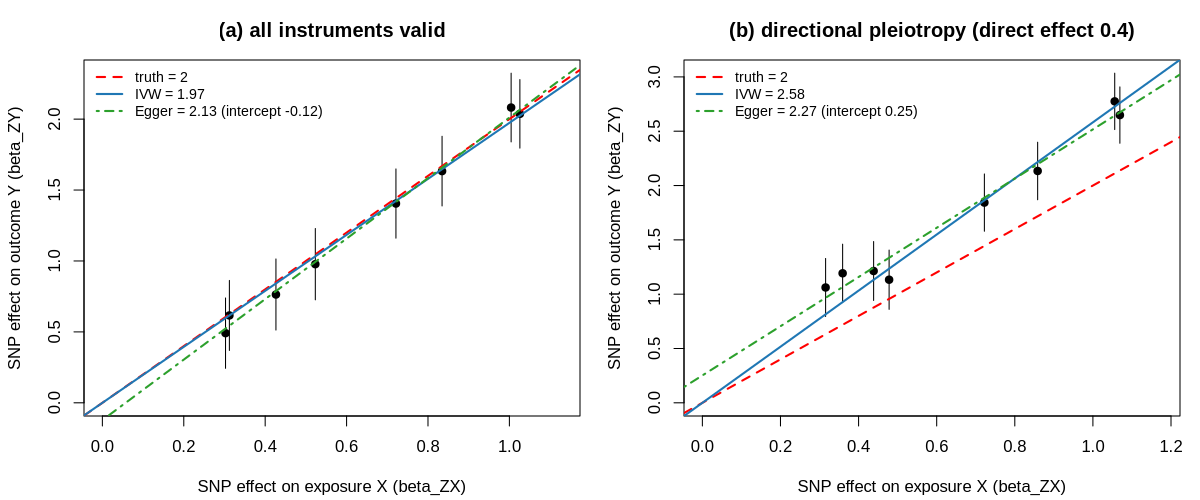

In [39]:
%%R -w 12 -h 5 -u in -r 100
set.seed(SEED + 6)
N7  <- 5000
Zv7 <- virtual_Z(N7)
PI7 <- seq(0.3, 1.2, length.out = K); PI7 <- PI7 * sqrt(VAR_G / sum(PI7^2))     # SNPs of different strength

# ---- one "GWAS" per SNP for the exposure and for the outcome (simple linear regressions)
snp_stats <- function(dd) {
  do.call(rbind, lapply(zcols, function(z) {
    sx_ <- unname(summary(lm(dd$X ~ dd[[z]]))$coefficients[2, 1:2]); sy_ <- unname(summary(lm(dd$Y ~ dd[[z]]))$coefficients[2, 1:2])
    data.frame(snp = z, bZX = sx_[1], seZX = sx_[2], bZY = sy_[1], seZY = sy_[2])
  }))
}
# ---- Wald ratios, IVW and MR-Egger from the table of per-SNP effects
mr_methods <- function(st) {
  sg <- sign(st$bZX); st$bZX <- st$bZX * sg; st$bZY <- st$bZY * sg               # orient every SNP so that its effect on X is positive
  st$wald <- st$bZY / st$bZX; st$se_wald <- st$seZY / abs(st$bZX)
  w <- 1 / st$seZY^2
  ivw  <- c(est = sum(st$bZX * st$bZY * w) / sum(st$bZX^2 * w), se = 1 / sqrt(sum(st$bZX^2 * w)))
  eg   <- lm(bZY ~ bZX, data = st, weights = w); s <- summary(eg); sc <- min(1, s$sigma)   # residual scale, not allowed below 1
  list(st = st, ivw = ivw, egger = c(est = unname(coef(eg)[2]), se = s$coefficients[2, 2] / sc, intercept = unname(coef(eg)[1]), se_int = s$coefficients[1, 2] / sc))
}
scatter_mr <- function(res, title) {
  st <- res$st
  plot(st$bZX, st$bZY, pch = 19, xlim = c(0, max(st$bZX) * 1.1), ylim = range(c(0, st$bZY + 1.96 * st$seZY, st$bZY - 1.96 * st$seZY)),
       xlab = "SNP effect on exposure X (beta_ZX)", ylab = "SNP effect on outcome Y (beta_ZY)", main = title)
  segments(st$bZX, st$bZY - 1.96 * st$seZY, st$bZX, st$bZY + 1.96 * st$seZY)
  abline(0, BETA, col = "red", lty = 2, lwd = 2); abline(0, res$ivw["est"], col = "#1f77b4", lwd = 2)
  abline(res$egger["intercept"], res$egger["est"], col = "#2ca02c", lwd = 2, lty = 4)
  legend("topleft", c(paste("truth =", BETA), paste("IVW =", round(res$ivw["est"], 2)), paste0("Egger = ", round(res$egger["est"], 2), " (intercept ", round(res$egger["intercept"], 2), ")")),
         col = c("red", "#1f77b4", "#2ca02c"), lty = c(2, 1, 4), lwd = 2, bty = "n", cex = 0.85)
}

dd_a <- simulate_data(Zv7, PI = PI7, direct = rep(0, K))           # (a) all instruments valid
dd_b <- simulate_data(Zv7, PI = PI7, direct = rep(0.4, K))         # (b) every SNP has the same direct effect 0.4 on Y
res_a <- mr_methods(snp_stats(dd_a)); res_b <- mr_methods(snp_stats(dd_b))
par(mfrow = c(1, 2), mar = c(4.2, 4.2, 3, 1))
scatter_mr(res_a, "(a) all instruments valid"); scatter_mr(res_b, "(b) directional pleiotropy (direct effect 0.4)")

summ <- function(r, lab) data.frame(scenario = lab, IVW = r$ivw["est"], IVW_se = r$ivw["se"], Egger_slope = r$egger["est"], Egger_se = r$egger["se"],
                                    Egger_intercept = r$egger["intercept"], intercept_P = 2 * pnorm(-abs(r$egger["intercept"] / r$egger["se_int"])), row.names = NULL)
print(format(rbind(summ(res_a, "(a) valid"), summ(res_b, "(b) pleiotropic")), digits = 3), row.names = FALSE)
cat("\nper-SNP Wald ratios in scenario (a):", round(res_a$st$wald, 2), "\n")
mr_tab_a <- summ(res_a, "valid"); mr_tab_b <- summ(res_b, "pleiotropic")

**Reading the figure.** Each point is one SNP; the red dashed line has the true slope (2). In scenario **(a)** the points lie on a line through the origin: IVW and Egger agree with the truth and the Egger intercept is close to 0. In scenario **(b)** every point is shifted **upwards** by the direct effect, so the line through the origin (IVW) is **biased**, while **MR-Egger recovers the slope** and shows a **clearly non-zero intercept**: the signature of directional pleiotropy. With real data one has typically 10 to hundreds of SNPs, and MR-Egger has low power with few SNPs (we have K = 8), so interpret it cautiously.

## 8. When the Instrument Assumptions Fail

Instrumental variables are only as good as their assumptions. We now **break** the two untestable ones on purpose, with 2000 virtual butterflies so that noise does not hide the effect.

### 8.1 Pleiotropy (violation of the exclusion restriction) and a confounded instrument (violation of independence)

* **Pleiotropy:** the genotypes also affect fitness **directly**, not only via colour. We add a direct effect of size `a` × (first-stage effect). Theory: the IV estimate is biased by exactly **a**.
* **Confounded instrument:** the habitat is **correlated with the genotype** (`zc` > 0), as it would be if the instrument tracked population structure (butterflies from sunnier populations carry other alleles). IV then picks up the confounder.

OLS (grey) is shown for comparison: it is biased in every panel.

(a) bias when the genes act directly on Y (pleiotropy):
 strength naive_OLS IV_allele_score
     0.00      1.16         0.00587
     0.25      1.31         0.25526
     0.50      1.46         0.50510
     0.75      1.62         0.75594
     1.00      1.77         1.00450

(b) bias when the habitat is correlated with the instrument:
 strength naive_OLS IV_allele_score
      0.0      1.16         -0.0129
      0.1      1.21          0.2209
      0.2      1.26          0.4252
      0.3      1.32          0.6045
      0.5      1.43          0.9036


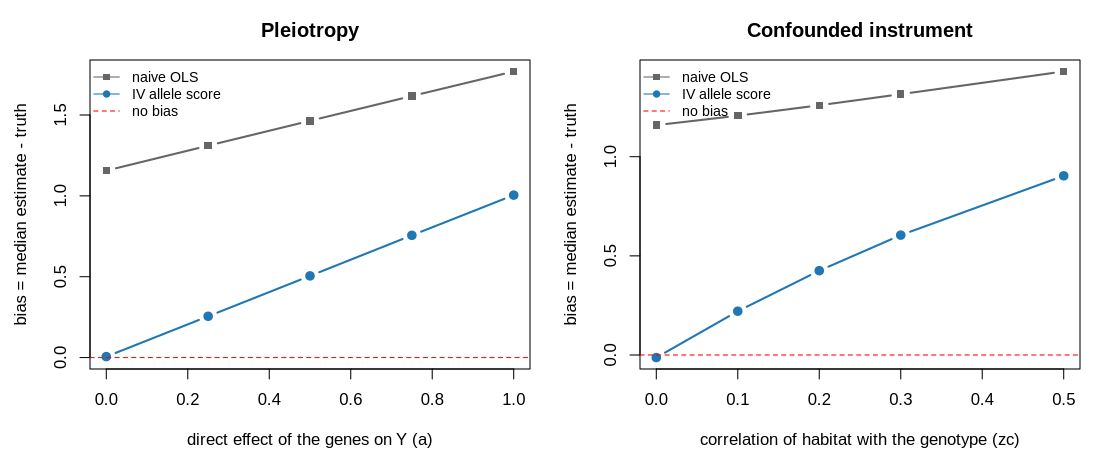

In [40]:
%%R -w 11 -h 4.6 -u in -r 100
pl_grid <- c(0, 0.25, 0.5, 0.75, 1)
res_pl <- do.call(rbind, lapply(pl_grid, function(a) {
  m <- mc_run(function() virtual_Z(2000), reps = 100, direct_scale = a, seed = SEED + 4)
  data.frame(strength = a, naive_OLS = median(m[, "ols"]) - BETA, IV_allele_score = median(m[, "ivs"]) - BETA)
}))
zc_grid <- c(0, 0.1, 0.2, 0.3, 0.5)
res_zc <- do.call(rbind, lapply(zc_grid, function(z) {
  m <- mc_run(function() virtual_Z(2000), reps = 100, zc = z, seed = SEED + 5)
  data.frame(strength = z, naive_OLS = median(m[, "ols"]) - BETA, IV_allele_score = median(m[, "ivs"]) - BETA)
}))
cat("(a) bias when the genes act directly on Y (pleiotropy):\n"); print(format(res_pl, digits = 3), row.names = FALSE)
cat("\n(b) bias when the habitat is correlated with the instrument:\n"); print(format(res_zc, digits = 3), row.names = FALSE)

par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3, 1))
for (nm in c("pl", "zc")) {
  r <- if (nm == "pl") res_pl else res_zc
  plot(r$strength, r$naive_OLS, type = "b", pch = 15, col = "grey40", lwd = 2, ylim = range(c(0, r$naive_OLS, r$IV_allele_score)),
       xlab = if (nm == "pl") "direct effect of the genes on Y (a)" else "correlation of habitat with the genotype (zc)",
       ylab = "bias = median estimate - truth", main = if (nm == "pl") "Pleiotropy" else "Confounded instrument")
  lines(r$strength, r$IV_allele_score, type = "b", pch = 19, col = "#1f77b4", lwd = 2); abline(h = 0, lty = 2, col = "red")
  legend("topleft", c("naive OLS", "IV allele score", "no bias"), col = c("grey40", "#1f77b4", "red"), lty = c(1, 1, 2), pch = c(15, 19, NA), bty = "n", cex = 0.85)
}

**Interpretation.** With a valid instrument (strength 0) the IV bias is zero while OLS is biased. As soon as the instrument is invalid, the IV bias grows with the violation, and a **strongly pleiotropic or confounded instrument can be worse than OLS**. Instrumental variables replace "no unmeasured confounding" by assumptions that are **not testable from the data**, which is why MR papers argue them biologically and add sensitivity analyses.

### 8.2 The Sargan test: detecting *some* invalid instruments

With **more instruments than exposures** (here K = 8 and one exposure) the **Sargan test** checks whether all instruments give the **same** causal estimate. If some of them have a direct effect on Y, their estimates disagree and the test rejects. We compare a data set with valid instruments with one in which **two of the eight SNPs** act directly on Y.

(The test cannot detect the case where *all* instruments are invalid in the same way, e.g. the confounded-instrument scenario above.)

In [41]:
%%R
set.seed(SEED + 7)
Zv  <- virtual_Z(2000)
dir_bad <- rep(0, K); dir_bad[1:2] <- 0.6                                    # SNPs 1 and 2 also act directly on Y
d_ok  <- simulate_data(Zv, seed = SEED + 7)
d_bad <- simulate_data(Zv, direct = dir_bad, seed = SEED + 7)
fit_ok  <- ivreg(f_all, data = d_ok)                                         # f_all: Y ~ X | Z1 + ... + ZK (from Section 6.8)
fit_bad <- ivreg(f_all, data = d_bad)
cat("ALL INSTRUMENTS VALID: beta_IV =", round(coef(fit_ok)["X"], 3), "(truth", BETA, ")\n")
print(round(summary(fit_ok,  diagnostics = TRUE)$diagnostics, 4))
cat("\nTWO INSTRUMENTS HAVE A DIRECT EFFECT ON Y: beta_IV =", round(coef(fit_bad)["X"], 3), "(truth", BETA, ")\n")
print(round(summary(fit_bad, diagnostics = TRUE)$diagnostics, 4))

ALL INSTRUMENTS VALID: beta_IV = 1.946 (truth 2 )
                 df1  df2 statistic p-value
Weak instruments   8 1991  394.2352  0.0000
Wu-Hausman         1 1997 8196.6006  0.0000
Sargan             7   NA    2.3752  0.9362

TWO INSTRUMENTS HAVE A DIRECT EFFECT ON Y: beta_IV = 2.16 (truth 2 )
                 df1  df2 statistic p-value
Weak instruments   8 1991  394.2352       0
Wu-Hausman         1 1997 6314.5724       0
Sargan             7   NA   37.9367       0


In the valid case the **Sargan** P-value is large (no evidence against the instruments). With two pleiotropic SNPs the P-value collapses and the 2SLS estimate is biased. In real MR work such a signal leads to **removing outlier SNPs** (e.g. MR-PRESSO), using **robust estimators** (median, MR-Egger, mode-based) or reconsidering the instruments.

## 9. The Real Morph as the Exposure: the M-Locus Variant as a Positive Control

In Sections 6 to 8 the exposure was a *simulated* colour score. Now we go back to the **real wing-pattern morph**: **X = 1 for *m*, 0 for *i*** (observed), with a real genotype as the instrument. We only have to invent the **outcome** (and the confounder), exactly as before:

$$Y_i=\beta\,X_i+\gamma\,C_i+\varepsilon_i,\qquad \beta=2,\ \gamma=3.$$

**The confounder must be independent of the instrument.** Here X is *given* (it is the real morph), so we cannot generate X from C. Instead we make the habitat C **correlated with the part of the morph that the instrument does not explain** (think: *which morph is found where* depends partly on local habitat, e.g. the abundance of the model species), and **orthogonal to the genotype**:

* `r_x` = the residual of `lm(X ~ Z)`. By the properties of least squares it is **uncorrelated with Z**;
* the noise part of C is also residualised on Z;
* so $C=\delta\,r_x/\mathrm{sd}(r_x)+e$ is uncorrelated with Z **by construction** and correlated with X.

(If the instrument predicts the morph *perfectly*, the residual is zero and there is no room for a confounder that is independent of Z: the code detects this and says so.)

**Which instrument?** The **M-locus control** (`ZM`: the best meta-analysis variant inside the M window of chromosome 26), if it exists, is the biologically motivated instrument for the morph; the **top hits** are the genome-wide winners of Section 3. We run the same analysis for every instrument and compare the first-stage *F* and the IV estimates. Remember the winner's curse: for the top hits the *F* below is inflated.

In [42]:
%%R -w 10 -h 4.4 -u in -r 100
BETA_M <- 2; GAMMA_M <- 3; DELTA_M <- 1           # true effect of the morph on Y, effect of C on Y, strength of the C-morph correlation

real_morph_iv <- function(z, seed = SEED + 9) {   # z = name of the instrument column in 'geno'
  set.seed(seed)
  zz <- geno[[z]]; Xm <- geno$x_morph; n <- length(Xm)
  r_x <- resid(lm(Xm ~ zz))                       # the part of the morph NOT explained by the genotype
  e   <- resid(lm(rnorm(n) ~ zz))                 # random noise, made uncorrelated with the genotype
  perfect <- sd(r_x) < 1e-6                       # the instrument predicts the morph perfectly: no room for confounding
  C2  <- if (perfect) e else DELTA_M * r_x / sd(r_x) + e
  Y2  <- BETA_M * Xm + GAMMA_M * C2 + rnorm(n, 0, SD_EY)
  dm  <- data.frame(Xm = Xm, Y2 = Y2, C2 = C2, Z = zz)
  list(dm = dm, perfect = perfect, cor_ZC = cor(zz, C2), row = {
    iv <- tsls_fit(Y2, Xm, zz); ol <- ols_fit(Y2, Xm)
    data.frame(instrument = z, role = inst$role[inst$id == z], R2_morph = cor(zz, Xm)^2, F_first_stage = unname(iv["F"]),
               OLS = unname(ol["beta"]), OLS_se = unname(ol["se"]), IV = unname(iv["beta"]), IV_se = unname(iv["se"]), row.names = NULL) })
}

ins_all <- c(zm_col, zcols)
runs <- lapply(ins_all, real_morph_iv); names(runs) <- ins_all
real_tab <- do.call(rbind, lapply(runs, function(r) r$row)); rownames(real_tab) <- NULL
cat("TRUE effect of the morph on Y =", BETA_M, "\n\n")
print(format(real_tab, digits = 3), row.names = FALSE)
cat("\ncorrelation between instrument and confounder (should be ~0):", format(sapply(runs, function(r) r$cor_ZC), digits = 2), "\n")
if (any(sapply(runs, function(r) r$perfect))) cat("NOTE: at least one instrument predicts the morph perfectly; there the confounder was set to pure noise.\n")

TRUE effect of the morph on Y = 2 

 instrument            role R2_morph F_first_stage  OLS OLS_se   IV IV_se
         ZM M-locus control    0.187          4.14 8.21   1.25 2.62  4.20
         Z1         top hit    0.679         38.10 5.86   1.61 2.54  2.17
         Z2         top hit    0.689         39.79 6.16   1.65 2.69  2.22
         Z3         top hit    0.700         41.98 6.34   1.77 2.43  2.38
         Z4         top hit    0.546         21.60 5.55   1.33 2.49  2.04
         Z5         top hit    0.621         29.46 6.63   1.64 2.59  2.41
         Z6         top hit    0.469         15.91 7.03   1.50 2.55  2.67
         Z7         top hit    0.570         23.86 7.11   1.58 2.88  2.48
         Z8         top hit    0.657         34.53 4.91   1.23 2.71  1.64

correlation between instrument and confounder (should be ~0): -6.9e-17  1.1e-16  4.1e-17  4.5e-17  8.4e-19 -3.7e-18  1.4e-16 -1.3e-16  9.9e-17 


### 9.1 Reading the table, and a closer look at one instrument

For each instrument the table gives: `R2_morph` (how much of the morph's variance it explains), the **first-stage *F***, the **naive OLS** estimate and the **IV** estimate with standard errors. A good instrument has *F* well above 10, an IV estimate near 2, and an OLS estimate that is clearly **above 2** (confounding). Notice how the **weak top hits** give very uncertain IV estimates, with huge standard errors, while an instrument that really tags the morph gives a precise answer.

Below we look more closely at **one instrument** (`ZM` if present, otherwise the best top hit) with `ivreg` and its diagnostics, in the same format as in Section 6.

instrument: ZM - M-locus control    (correlation with the confounder: 0 )


Call:
ivreg(formula = Y2 ~ Xm | Z, data = dm)

Residuals:
     Min       1Q   Median       3Q      Max 
-6.61359 -2.56239 -0.04047  1.82975 10.71468 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)
(Intercept)  0.01791    2.28973   0.008    0.994
Xm           2.61569    4.20348   0.622    0.542

Diagnostic tests:
                 df1 df2 statistic p-value  
Weak instruments   1  18     4.137  0.0570 .
Wu-Hausman         1  17     5.808  0.0276 *
Sargan             0  NA        NA      NA  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.063 on 18 degrees of freedom
Multiple R-Squared: 0.3777,	Adjusted R-squared: 0.3432 
Wald test: 0.3872 on 1 and 18 DF,  p-value: 0.5416 



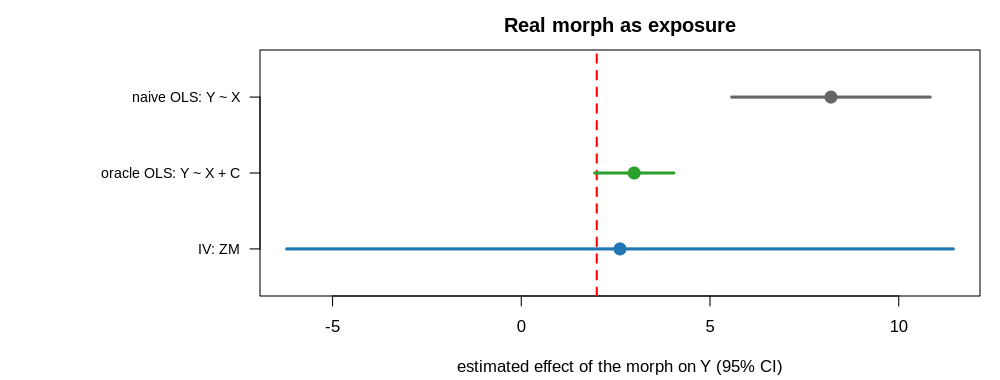

In [43]:
%%R -w 10 -h 3.8 -u in -r 100
zt <- if (length(zm_col) > 0) zm_col else zcols[1]
dm <- runs[[zt]]$dm
cat("instrument:", zt, "-", inst$role[inst$id == zt], "   (correlation with the confounder:", round(cor(dm$Z, dm$C2), 6), ")\n\n")
ols2 <- lm(Y2 ~ Xm, data = dm); orc2 <- lm(Y2 ~ Xm + C2, data = dm); iv2 <- ivreg(Y2 ~ Xm | Z, data = dm)
print(summary(iv2, diagnostics = TRUE))

tab2 <- rbind(ci_row(ols2, "naive OLS: Y ~ X", "Xm"), ci_row(orc2, "oracle OLS: Y ~ X + C", "Xm"), ci_row(iv2, paste0("IV: ", zt), "Xm"))
cols2 <- c("grey40", "#2ca02c", "#1f77b4")
par(mar = c(4.2, 13, 2.5, 1)); yy <- rev(seq_len(nrow(tab2)))
plot(NA, xlim = range(c(tab2$lo, tab2$hi, BETA_M)), ylim = c(0.5, 3.5), yaxt = "n", ylab = "", xlab = "estimated effect of the morph on Y (95% CI)",
     main = "Real morph as exposure")
abline(v = BETA_M, lty = 2, col = "red", lwd = 2); segments(tab2$lo, yy, tab2$hi, yy, lwd = 3, col = cols2); points(tab2$estimate, yy, pch = 19, cex = 1.6, col = cols2)
axis(2, at = yy, labels = tab2$method, las = 1, cex.axis = 0.85)

**Take-home message of this section.** MR works when the instrument is **relevant** (a real, replicated association with the exposure), **independent of the confounders** and **acts only through the exposure**. For the *m*/*i* morph the natural instrument is the **M locus** (a well-characterised region on chromosome 26), not the genome-wide top hits of a 20-butterfly GWAS: these have first-stage statistics inflated by the winner's curse and, as the meta-analysis showed, do not even pass a multiple-testing threshold. In a real MR study the exposure GWAS would come from a **large independent sample**, and the instruments would be **LD-clumped, genome-wide significant** variants.

## 10. Discussion and Suggestions of Improvement

### 10.1 What did we learn?

1. **Confounding bias does not vanish with more data.** Naive regression converged to the wrong value (Section 6.11).
2. **An instrument breaks the link between the exposure and the confounder**: only the genetically determined part of X is used. The IV estimate recovered the truth *without ever seeing C*.
3. **Strength matters.** A single weak SNP, or many weak SNPs in a tiny sample, give unstable estimates biased towards OLS (Sections 6.8 to 6.10). An **allele score** is the pragmatic solution.
4. **Validity cannot be proved from the data.** Pleiotropy and confounded instruments bias IV estimates, sometimes worse than OLS (Section 8). Sargan and MR-Egger detect *some* violations.
5. **Selection of instruments from the same data inflates their strength (winner's curse)**; relevance must be shown in an independent sample (Sections 3, 4.4, 9).
6. **MR and meta-analysis are cousins**: the IVW estimator is a fixed-effect meta-analysis of per-SNP Wald ratios, with the same weights as in the previous notebook (Section 7).

### 10.2 Butterfly biology and the IV assumptions

* **Relevance.** The m/i morph is controlled by a **single, strong-effect locus**, so a variant at (or tightly linked to) it is a very strong instrument for the morph. This makes relevance *easy*, and the **exclusion restriction hard**: a supergene-like region contains **many linked genes**, any of which might affect fitness traits directly (**pleiotropy by linkage**).
* **Independence.** Genotype at the locus is inherited at random **within a population**, but **between populations** allele frequencies and habitats differ: population structure is the main threat to the independence assumption in natural populations. Include population labels or principal components as covariates (in `ivreg` they enter on **both sides of the `|`**, e.g. `ivreg(Y ~ X + PC1 | Z + PC1)`).
* **The outcome.** In a real study Y could be a measured fitness component (survival, mating success, predation marks on the wings, fecundity). Exposure and outcome must be measured on the **same or comparable** butterflies.
* **Sample size.** MR typically needs hundreds to thousands of individuals; 20 butterflies are enough only for a demonstration.

### 10.3 Exercises

1. **Change the confounding.** Set `GAMMA <- 0` in Section 6.2 and re-run Sections 6.4 onward. What happens to the naive estimate? Does `ivreg` still work? (No confounding: OLS is fine and IV is only less precise.)
2. **Make the instrument stronger or weaker.** Change `VAR_G` (for example 0.5 or 16). When does the single-SNP IV become usable?
3. **Use fewer or more instruments.** Re-run Section 3 with `N_INSTRUMENTS = 4` and with `N_INSTRUMENTS = 15` (increase `TOP_N` in the meta-analysis notebook first). How do the "all SNPs separately" and "allele score" estimates change?
4. **Invalid instruments.** In Section 8.2 put the direct effect on **all** SNPs. Does Sargan still detect it? Why not?
5. **Binary exposure.** Replace the simulated continuous X by `X <- as.numeric(g + DELTA * C + rnorm(n) > 0)` in `simulate_data`. Two-stage least squares with a linear first stage still estimates the effect on the **linear-probability scale**. Compare with the true effect.
6. **Population structure.** In Section 8.1 the parameter `zc` mimics it. Add a "population" covariate to `ivreg` (Section 10.2) to see whether it helps when the confounder is measured.

### 10.4 Where to go next

R packages for real MR analyses: **TwoSampleMR** (MR-Base; connects to published GWAS summary statistics), **MendelianRandomization**, **MR-PRESSO**, **mr.raps**; for multiple exposures, **MVMR**. Methods to learn about: weighted-median and mode-based estimators, MR with binary outcomes, bidirectional MR, colocalisation (to separate "same causal variant" from "linked variants").

## 11. Save the Results to Google Drive

R writes the main result tables next to the genotype tables in `mendelian_randomization_HypMis/tables/`. (Figures are shown in the notebook; right-click a figure to save it, or re-run the cell after adding `png(...)` / `dev.off()` around the plotting code.)

In [44]:
%%R
w <- function(x, name) write.table(x, file.path(mr_dir, name), sep = "\t", quote = FALSE, row.names = FALSE)
w(d_tab,   "mr_single_dataset_estimates.tsv")        # one simulated data set of 20 butterflies (Section 6.8)
w(mc_tab,  "mr_montecarlo_2000_replicates.tsv")      # 2000 replicates with the real genotypes (Section 6.9)
w(res_str, "mr_instrument_strength_scan.tsv")        # Section 6.10
w(res_n,   "mr_sample_size_scan.tsv")                # Section 6.11
w(rbind(mr_tab_a, mr_tab_b), "mr_summary_data_ivw_egger.tsv")   # Section 7
w(res_pl,  "mr_violation_pleiotropy.tsv"); w(res_zc, "mr_violation_confounded_instrument.tsv")   # Section 8
w(real_tab, "mr_real_morph_instruments.tsv")         # Section 9
cat("written to", mr_dir, ":\n"); cat(paste(" ", list.files(mr_dir, pattern = "^mr_.*tsv$")), sep = "\n")

written to /content/drive/MyDrive/GWAS/mendelian_randomization_HypMis/tables :
  mr_instrument_strength_scan.tsv
  mr_montecarlo_2000_replicates.tsv
  mr_real_morph_instruments.tsv
  mr_sample_size_scan.tsv
  mr_single_dataset_estimates.tsv
  mr_summary_data_ivw_egger.tsv
  mr_violation_confounded_instrument.tsv
  mr_violation_pleiotropy.tsv


In [45]:
# Overview of everything this notebook produced on Google Drive.
for f in sorted(D["tables"].glob("*")) + sorted(D["figures"].glob("*.png")) + sorted(D["angsd"].glob("mr_sites*")):
    print(f"{f.stat().st_size / 1e3:9.1f} kB  {f.relative_to(PROJECT_DIR)}")

      3.9 kB  mendelian_randomization_HypMis/tables/genotypes_dosage.tsv
      0.8 kB  mendelian_randomization_HypMis/tables/instruments.tsv
      0.8 kB  mendelian_randomization_HypMis/tables/mr_instrument_strength_scan.tsv
      0.6 kB  mendelian_randomization_HypMis/tables/mr_montecarlo_2000_replicates.tsv
      1.1 kB  mendelian_randomization_HypMis/tables/mr_real_morph_instruments.tsv
      1.6 kB  mendelian_randomization_HypMis/tables/mr_sample_size_scan.tsv
      0.6 kB  mendelian_randomization_HypMis/tables/mr_single_dataset_estimates.tsv
      0.3 kB  mendelian_randomization_HypMis/tables/mr_summary_data_ivw_egger.tsv
      0.2 kB  mendelian_randomization_HypMis/tables/mr_violation_confounded_instrument.tsv
      0.2 kB  mendelian_randomization_HypMis/tables/mr_violation_pleiotropy.tsv
    143.0 kB  mendelian_randomization_HypMis/figures/instrument_dosages.png
      9.2 kB  mendelian_randomization_HypMis/angsd/mr_sites.arg
      0.8 kB  mendelian_randomization_HypMis/angsd/mr_

## 12. Summary

| Step | What we did | Where |
|---|---|---|
| Instruments | independent top variants of the meta-analysis + the M-locus control | Section 3 |
| Genotypes | ANGSD genotype likelihoods at those sites → dosages (Z) | Section 4 |
| Simulation | habitat C (unmeasured), colour X, fitness Y with known β | Section 6.2-6.3 |
| Naive vs oracle | confounding bias, and the impossible-in-practice fix | Sections 6.4-6.5 |
| 2SLS | by hand, with `ivreg`, with diagnostics | Sections 6.6-6.8 |
| Monte Carlo | bias, spread, coverage; weak instruments; sample size | Sections 6.9-6.11 |
| Summary-data MR | Wald ratio, IVW, MR-Egger | Section 7 |
| Failure modes | pleiotropy, confounded instrument, Sargan | Section 8 |
| Real morph | M locus as a positive control | Section 9 |

> **One-sentence summary.** Ordinary regression of fitness on wing colour is biased by an unmeasured habitat effect, whereas a genetic instrument that predicts colour, is independent of habitat and acts only through colour recovers the causal effect, as long as the instrument is strong and valid.

### References

* Davey Smith G, Ebrahim S (2003). *'Mendelian randomization': can genetic epidemiology contribute to understanding environmental determinants of disease?* Int J Epidemiol 32:1-22.
* Lawlor DA, Harbord RM, Sterne JAC, Timpson N, Davey Smith G (2008). *Mendelian randomization: using genes as instruments for making causal inferences in epidemiology.* Stat Med 27:1133-1163.
* Staiger D, Stock JH (1997). *Instrumental variables regression with weak instruments.* Econometrica 65:557-586.
* Burgess S, Thompson SG (2011). *Avoiding bias from weak instruments in Mendelian randomization studies.* Int J Epidemiol 40:755-764.
* Burgess S, Butterworth A, Thompson SG (2013). *Mendelian randomization analysis with multiple genetic variants using summarized data.* Genet Epidemiol 37:658-665.
* Bowden J, Davey Smith G, Burgess S (2015). *Mendelian randomization with invalid instruments: effect estimation and bias detection through Egger regression.* Int J Epidemiol 44:512-525.
* Sargan JD (1958). *The estimation of economic relationships using instrumental variables.* Econometrica 26:393-415.
* Hemani G, et al. (2018). *The MR-Base platform supports systematic causal inference across the human phenome.* eLife 7:e34408.
* Fox J, Kleiber C, Zeileis A. *ivreg: Instrumental-Variables Regression by 2SLS, 2SM or 2SMM, with Diagnostics.* R package (CRAN).
* Korneliussen TS, Albrechtsen A, Nielsen R (2014). *ANGSD: Analysis of Next Generation Sequencing Data.* BMC Bioinformatics 15:356.
* Skotte L, Korneliussen TS, Albrechtsen A (2012). *Association testing for next-generation sequencing data using score statistics.* Genet Epidemiol 36:430-437.

In [46]:
!jupyter nbconvert --to html /content/drive/MyDrive/GWAS/Mendelian_Randomization_ivreg_Hypolimnas_misippus_Colab.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/GWAS/Mendelian_Randomization_ivreg_Hypolimnas_misippus_Colab.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 9 image(s).
[NbConvertApp] Writing 1281452 bytes to /content/drive/MyDrive/GWAS/Mendelian_Randomization_ivreg_Hypolimnas_misippus_Colab.html
